

# 1. Start with the business question

Define the question as:

> Can we predict whether a residential property will appreciate above a meaningful threshold, based on neighborhood factors such as crime, median income, and subway accessibility?


> Build separate predictive models for different building classes.

---

# 2. Build the raw property-sale base table

Create one property-level dataset where each record represents a property that sold more than once.

For each property, identify:

* first sale price
* last sale price
* first sale date
* last sale date
* building class
* neighborhood
* property identifier such as BBL

Then derive:

* total price change
* percent price change
* holding period in days or years


---

# 3. Clean the raw sales data

## 3.1 Remove invalid or non-market transactions

Exclude transactions that are not meaningful market sales, such as:

* sale prices that are extremely low
* $0, $1, $10, or similarly nominal prices
* obvious family transfers or bookkeeping transfers if identifiable

---

## 3.2 Remove impossible or highly suspicious appreciation values

Filter out properties with extremely unrealistic changes, for example:

* huge positive jumps that are clearly not normal market appreciation
* impossible negative values caused by data issues

---

## 3.3 Remove short holding periods

Remove properties resold too quickly, such as:

* less than 6 months
* or preferably less than 1 year

---

## 3.4 Remove duplicates

If the same property has the same sale date and sale price repeated, deduplicate.

---

## 3.5 Check missing values

Review missingness in:

* building class
* neighborhood
* sale price
* sale dates
* any future external features like crime, income, subway distance

---

# 4. Decide the property segments you will model

Create separate datasets by building class.

Example:

* one-family dwellings
* two-family dwellings
* condo categories


---

# 5. Create the outcome measure properly

Do not rely only on raw total percent change, because a property held for 10 years and one held for 2 years are not directly comparable.

Create a normalized appreciation measure such as:

* annualized return
  or
* annualized percent growth


---

# 6. Set the threshold for “high growth”

as we are building different models for different building classes, the threshold should be defined **within each class**, not globally.

Best approach:

## 6.1 Using a percentile-based threshold within each building class

For each building class:

* rank properties by annualized return
* define the top portion as high-growth

Recommended:

* 75th percentile = top 25% performers

That means:

* target = 1 if the property’s annualized return is above the 75th percentile for its building class
* target = 0 otherwise

Why this is best:

* fair comparison within peers
* avoids problems caused by co-ops and other classes behaving differently
* gives a balanced and defensible classification target

Possible alternatives:

* 80th percentile if you want a stricter target
* 90th percentile if you want only elite performers, though this may make the classes too imbalanced

For your project, **75th percentile within building class** is the best choice.

---

# 7. Bring in external neighborhood features


## 7.1 Crime

Attach a crime variable to each property based on neighborhood, ZIP code, census tract, or another location unit.

Possible versions:

* total crime rate
* violent crime rate
* crime incidents per capita

---

## 7.2 Median income

Possible versions:

* median household income
* income percentile within NYC
* binned income category

---

## 7.3 Subway accessibility


Possible versions:

* distance to nearest subway station
* number of stations within a radius
* binary flag for near subway
* transit accessibility bucket such as very close, close, far

This is often more useful than using raw coordinates alone.

---

# 8. Create the modeling dataset

At this stage, each row should represent one property, with:

## Outcome

* annualized return
* high-growth target variable

## Core identifiers

* property id
* building class
* neighborhood

## Predictors

* crime
* median income
* subway accessibility

Optional additional controls if available:

* building age
* number of units
* square footage
* borough
* prior sale price level

---

# 9. Prepare data for modeling

Before modeling, do the following:

## 9.1 Handle feature missingness

For example:

* remove rows missing too many important features
* impute neighborhood features where appropriate

## 9.2 Standardize or encode variables where needed

Examples:

* scale continuous variables if needed for logistic regression
* convert categorical fields such as neighborhood or borough into encoded form
* bin skewed continuous variables if that improves interpretability

## 9.3 Check class balance

For each building class model, inspect how many observations are target 1 vs target 0.

If the positive class is too rare:

* reconsider the threshold
* or use class weighting during modeling

---

# 10. Do descriptive analytics before modeling

This still belongs to preparation and helps justify your modeling decisions.

Show:

* distribution of annualized return overall
* distribution by building class
* number of properties in each class
* average crime, income, subway distance by class
* target rate by building class
* maybe borough or neighborhood summaries

This demonstrates data understanding and explains why separate models are justified.

---

# 11. Step 3 begins: define hypotheses

Create clear hypotheses tied to your variables.

Examples:

* Higher neighborhood median income increases the likelihood of high property appreciation
* Higher crime lowers the likelihood of high appreciation
* Better subway access increases the likelihood of high appreciation
* The importance of these factors differs by building class

These hypotheses should be shown before the models.

---

# 12. Split into separate modeling datasets

For each building class:

* create one dataset
* keep the same feature structure
* same target logic within that class
* same train/test methodology

You are now ready to build one model per class.

---

# 13. Train-test split

For each class:

* split data into training and testing sets
* use the same split rule across all models for consistency

This ensures fair comparison between methods.

If sample size is smaller in some classes, use cross-validation in addition to a train/test split.

---

# 14. Build 3 to 4 models for each building class

Your professor wants model comparison, so use multiple algorithms.

Recommended set:

* Logistic Regression
* Decision Tree
* Random Forest
* Gradient Boosting or XGBoost if available

Why:

* Logistic Regression gives interpretability and a baseline
* Tree models capture non-linear effects
* Random Forest and Boosting usually perform better for this kind of problem

---

# 15. Evaluate each model

For every building class, compare all models using:

## 15.1 ROC curve

Show ROC curves on the same chart for the models in that class.

## 15.2 AUC

Report the AUC for each model.

## 15.3 Lift analysis

Show whether the model can concentrate high-growth properties in the top predicted deciles.

## 15.4 Confusion-matrix-based metrics

Also review:

* precision
* recall
* F1 score

This helps you explain business usefulness, not just statistical fit.

---

# 16. Select the best model for each building class

Choose based on:

* highest AUC
* strongest lift
* stability
* interpretability

You may find:

* Random Forest best for one-family homes
* Gradient Boosting best for condos
* Logistic Regression still useful for interpretation

That is okay. Different classes can have different best models.

---

# 17. Interpret feature importance

For the final selected model in each class, explain which features matter most.

Examples:

* median income is the strongest predictor for condos
* subway proximity matters more for co-ops
* crime is more important in one-family housing markets

This is where you turn technical results into business insights.

---

# 18. Explain results in business language

This part matters a lot for grading.

Translate the model into non-technical meaning, such as:

* Properties in higher-income neighborhoods are more likely to outperform similar properties
* Access to subway stations improves the probability of above-threshold appreciation
* Neighborhood crime reduces appreciation potential, though the effect differs across building types

Also explain what the model is useful for:

* investors
* buyers
* developers
* urban planners

---

# 19. Show limitations

Include a final section on model risk and study limitations, for example:

* appreciation may be influenced by factors not captured in the dataset
* some sales may still contain noise
* crime and income are neighborhood-level variables and may not fully capture block-level effects
* results are specific to NYC and the time period studied

This makes the project look mature and credible.

---

# 20. Final presentation flow

Your final Step 3 presentation should go in this order:

1. Business question
2. Why separate building-class models
3. Cleaning decisions
4. Target definition and threshold logic
5. Feature set: crime, income, subway
6. Hypotheses
7. Models compared
8. ROC curves
9. AUC table
10. Lift analysis
11. Best model selection
12. Feature importance
13. Business implications
14. Limitations


# BUS 9430 Final Project
## NYC Residential Property Appreciation
### Separate Models & Thresholds by Building Class

---
## STEP 1 — Load Data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import numpy as np



In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
base_path = '/content/drive/MyDrive/BUS 9430 Data/'

mta     = pd.read_csv(base_path + 'MTA_Subway_Stations.csv')
nypd    = pd.read_csv(base_path + 'NYPD_Complaint_Data_Current_(Year_To_Date)_20260324.csv')
housing = pd.read_csv(base_path + 'NYC_Citywide_Annualized_Calendar_Sales_Update_20260324.csv',
                      on_bad_lines='skip')
income  = pd.read_csv(base_path + 'Median Incomes.csv')

print(f"MTA     : {mta.shape}")
print(f"NYPD    : {nypd.shape}")
print(f"Housing : {housing.shape}")
print(f"Income  : {income.shape}")

/tmp/ipykernel_4679/2333385934.py:5: DtypeWarning: Columns (11,12,13,14,15) have mixed types. Specify dtype option on import or set low_memory=False.
  housing = pd.read_csv(base_path + 'NYC_Citywide_Annualized_Calendar_Sales_Update_20260324.csv',


MTA     : (496, 19)
NYPD    : (579561, 36)
Housing : (760914, 29)
Income  : (4685, 6)


In [ ]:
print(f"MTA Dataset: {mta.shape[0]} rows, {mta.shape[1]} columns")

mta_table = pd.DataFrame({
    "Column": mta.columns,
    "Data Type": mta.dtypes.values,
    "Missing Values": mta.isnull().sum().values
})

mta_table = mta_table[[
    "Column",
    "Data Type",
    "Missing Values"
]]

mta_table

MTA Dataset: 496 rows, 19 columns


,Column,Data Type,Missing Values
0,GTFS Stop ID,object,0
1,Station ID,int64,0
2,Complex ID,int64,0
3,Division,object,0
4,Line,object,0
5,Stop Name,object,0
6,Borough,object,0
7,CBD,bool,0
8,Daytime Routes,object,0
9,Structure,object,0


In [ ]:
print(f"NYPD Dataset: {nypd.shape[0]} rows, {nypd.shape[1]} columns")

nypd_table = pd.DataFrame({
    "Column": nypd.columns,
    "Data Type": nypd.dtypes.values,
    "Missing Values": nypd.isnull().sum().values
})

# Sort by missing values
nypd_table = nypd_table.sort_values(by="Missing Values", ascending=False)

nypd_table

NYPD Dataset: 579561 rows, 36 columns


,Column,Data Type,Missing Values
26,TRANSIT_DISTRICT,float64,544947
9,HOUSING_PSA,float64,543632
5,CMPLNT_TO_DT,object,26380
18,PD_CD,float64,309
3,CMPLNT_FR_DT,object,0
2,BORO_NM,object,0
1,ADDR_PCT_CD,int64,0
0,CMPLNT_NUM,object,0
7,CRM_ATPT_CPTD_CD,object,0
8,HADEVELOPT,object,0


In [ ]:
print(f"Housing Dataset: {housing.shape[0]} rows, {housing.shape[1]} columns")

housing_table = pd.DataFrame({
    "Column": housing.columns,
    "Data Type": housing.dtypes.values,
    "Missing Values": housing.isnull().sum().values
})

# Sort by missing values
housing_table = housing_table.sort_values(by="Missing Values", ascending=False)

housing_table

Housing Dataset: 760914 rows, 29 columns


,Column,Data Type,Missing Values
6,EASE-MENT,float64,760914
9,APARTMENT NUMBER,object,572920
14,LAND SQUARE FEET,object,187695
15,GROSS SQUARE FEET,object,187692
12,COMMERCIAL UNITS,object,176542
11,RESIDENTIAL UNITS,object,113003
13,TOTAL UNITS,object,101852
16,YEAR BUILT,float64,33871
25,BIN,float64,24408
26,BBL,float64,24408


In [ ]:
print(f"Income Dataset: {income.shape[0]} rows, {income.shape[1]} columns")

income_table = pd.DataFrame({
    "Column": income.columns,
    "Data Type": income.dtypes.values,
    "Missing Values": income.isnull().sum().values
})

# Sort by missing values
income_table = income_table.sort_values(by="Missing Values", ascending=False)

income_table

Income Dataset: 4685 rows, 6 columns


,Column,Data Type,Missing Values
3,Unnamed: 3,object,4
2,Unnamed: 2,object,4
4,Unnamed: 4,object,4
5,Unnamed: 5,object,4
1,Median Incomes,object,1
0,Name,object,1


In [ ]:
income.head(20)

,Name,Median Incomes,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5
0,Description,Median is used as a measure for income because...,NaN,NaN,NaN,NaN
1,Source Notes,"U.S. Census Bureau, American Community Survey ...",NaN,NaN,NaN,NaN
2,Notes,Dollar amounts for all years adjusted to const...,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN
4,Location,Household Type,TimeFrame,DataFormat,Data,Fips
5,New York City,All Households,2023,Dollars,76577,3651000
6,New York City,Families,2023,Dollars,88053,3651000
7,New York City,Families with Children,2023,Dollars,80530,3651000
8,New York City,Families without Children,2023,Dollars,92415,3651000
9,New York City,All Households,2022,Dollars,77549.62618,3651000


---
## STEP 2 — Clean  Dataset

### 2A — Housing

In [ ]:
# ── Drop columns we won't use ──────────────────────────────────────────────
drop_cols = [
    'EASE-MENT', 'Community Board', 'Council District',
    'TAX CLASS AS OF FINAL ROLL', 'BUILDING CLASS AS OF FINAL ROLL',
    'TAX CLASS AT TIME OF SALE', 'BIN',
    'Census Tract 2020', 'Neighborhood Tabulation Area (NTA) (2020)'
]
housing = housing.drop(columns=[c for c in drop_cols if c in housing.columns])

# ── Map borough codes to names ─────────────────────────────────────────────
borough_map = {1:'Manhattan', 2:'Bronx', 3:'Brooklyn', 4:'Queens', 5:'Staten Island'}
housing['BOROUGH'] = housing['BOROUGH'].replace(borough_map)

# ── Parse SALE PRICE ──────────────────────────────────────────────────────
housing['SALE PRICE'] = (
    housing['SALE PRICE'].astype(str)
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False)
    .pipe(pd.to_numeric, errors='coerce')
)

# ── Parse SALE DATE ───────────────────────────────────────────────────────
housing['SALE DATE'] = pd.to_datetime(housing['SALE DATE'], errors='coerce')

# ── Clean BUILDING CLASS CATEGORY whitespace ──────────────────────────────
housing['BUILDING CLASS CATEGORY'] = (
    housing['BUILDING CLASS CATEGORY'].astype(str)
    .str.strip()
    .str.replace(r'\s+', ' ', regex=True)
)

print("Housing cleaned shape:", housing.shape)

Housing cleaned shape: (760914, 20)


In [ ]:
# ── Keep only residential categories ──────────────────────────────────────
residential_categories = [
    '01 ONE FAMILY DWELLINGS',
    '02 TWO FAMILY DWELLINGS',
    '03 THREE FAMILY DWELLINGS',
    '09 COOPS - WALKUP APARTMENTS',
    '10 COOPS - ELEVATOR APARTMENTS',
    '12 CONDOS - WALKUP APARTMENTS',
    '13 CONDOS - ELEVATOR APARTMENTS',
    '15 CONDOS - 2-10 UNIT RESIDENTIAL',
]

housing_res = housing[
    housing['BUILDING CLASS CATEGORY'].isin(residential_categories)
].copy()

# ── Summary ───────────────────────────────────────────────────────────────
print(f"Original rows      : {housing.shape[0]:,}")
print(f"Residential rows   : {housing_res.shape[0]:,}")

retained_pct = housing_res.shape[0] / housing.shape[0] * 100
print(f"Percentage retained: {retained_pct:.2f}%")

print("\nCategory breakdown:")
print(housing_res['BUILDING CLASS CATEGORY'].value_counts())

Original rows      : 760,914
Residential rows   : 630,274
Percentage retained: 82.83%

Category breakdown:
BUILDING CLASS CATEGORY
01 ONE FAMILY DWELLINGS              168189
02 TWO FAMILY DWELLINGS              142212
10 COOPS - ELEVATOR APARTMENTS       118443
13 CONDOS - ELEVATOR APARTMENTS      116020
03 THREE FAMILY DWELLINGS             39895
09 COOPS - WALKUP APARTMENTS          24005
15 CONDOS - 2-10 UNIT RESIDENTIAL     13055
12 CONDOS - WALKUP APARTMENTS          8455
Name: count, dtype: int64


In [ ]:
# ── Assign broad segment labels we will model separately ──────────────────
segment_map = {
    '01 ONE FAMILY DWELLINGS'            : 'One-Family',
    '02 TWO FAMILY DWELLINGS'            : 'Two-Family',
    '03 THREE FAMILY DWELLINGS'          : 'Three-Family',
    '09 COOPS - WALKUP APARTMENTS'       : 'Co-op',
    '10 COOPS - ELEVATOR APARTMENTS'     : 'Co-op',
    '12 CONDOS - WALKUP APARTMENTS'      : 'Condo',
    '13 CONDOS - ELEVATOR APARTMENTS'    : 'Condo',
    '15 CONDOS - 2-10 UNIT RESIDENTIAL'  : 'Condo',
}

housing_res['SEGMENT'] = housing_res['BUILDING CLASS CATEGORY'].map(segment_map)

# ── Drop any unmapped rows (safety step) ──────────────────────────────────
housing_res = housing_res.dropna(subset=['SEGMENT'])

# ── Summary ───────────────────────────────────────────────────────────────
print("Segment counts:")
print(housing_res['SEGMENT'].value_counts())

print("\nSegment distribution (%):")
print((housing_res['SEGMENT'].value_counts(normalize=True) * 100).round(2))

Segment counts:
SEGMENT
One-Family      168189
Co-op           142448
Two-Family      142212
Condo           137530
Three-Family     39895
Name: count, dtype: int64

Segment distribution (%):
SEGMENT
One-Family      26.69
Co-op           22.60
Two-Family      22.56
Condo           21.82
Three-Family     6.33
Name: proportion, dtype: float64


### 2B — MTA Subway Stations

In [ ]:
# ── Drop unnecessary columns ──────────────────────────────────────────────
mta_drop = [
    'ADA Northbound','ADA','ADA Southbound','ADA Notes',
    'CBD','GTFS Stop ID','Complex ID','Division'
]
mta = mta.drop(columns=[c for c in mta_drop if c in mta.columns])

# ── Rename coordinate columns ─────────────────────────────────────────────
coord_rename = {}
for col in mta.columns:
    if 'latitude' in col.lower() or col.lower() == 'gtfs latitude':
        coord_rename[col] = 'LATITUDE'
    if 'longitude' in col.lower() or col.lower() == 'gtfs longitude':
        coord_rename[col] = 'LONGITUDE'

mta = mta.rename(columns=coord_rename)

# ── Convert to numeric ────────────────────────────────────────────────────
mta['LATITUDE'] = pd.to_numeric(mta['LATITUDE'], errors='coerce')
mta['LONGITUDE'] = pd.to_numeric(mta['LONGITUDE'], errors='coerce')

# ── Remove missing coordinates ────────────────────────────────────────────
mta = mta.dropna(subset=['LATITUDE','LONGITUDE'])

# ── Remove duplicates ─────────────────────────────────────────────────────
mta = mta.drop_duplicates(subset=['LATITUDE','LONGITUDE'])

# ── Clean station name (if exists) ────────────────────────────────────────
if 'Stop Name' in mta.columns:
    mta['Stop Name'] = mta['Stop Name'].astype(str).str.strip().str.upper()

# ── Final check ───────────────────────────────────────────────────────────
print("MTA stations after cleaning:", mta.shape[0])
mta.head(3)

MTA stations after cleaning: 493


,Station ID,Line,Stop Name,Borough,Daytime Routes,Structure,LATITUDE,LONGITUDE,North Direction Label,South Direction Label,Georeference
0,317,Broadway - 7Av,TIMES SQ-42 ST,M,1 2 3,Subway,40.755290,-73.987495,Uptown,Downtown,POINT (-73.987495 40.75529)
1,515,Staten Island,ANNADALE,SI,SIR,Open Cut,40.540460,-74.178217,Ferry,South Shore,POINT (-74.178217 40.54046)
2,139,Franklin Shuttle,FRANKLIN AV,Bk,S,Elevated,40.680596,-73.955827,Last Stop,Prospect Park,POINT (-73.955827 40.680596)


### 2C — Income

In [ ]:
income = income.drop(index=range(4))
income.columns = income.iloc[0]
income = income[1:].reset_index(drop=True)
income = income.rename(columns={'DataFormat': 'Currency', 'Data': 'Income'})

# Keep only the neighborhood / NTA name and income value
# (column names may differ — print them to confirm)
print("Income columns:", income.columns.tolist())
income.head()

Income columns: ['Location', 'Household Type', 'TimeFrame', 'Currency', 'Income', 'Fips']


4,Location,Household Type,TimeFrame,Currency,Income,Fips
0,New York City,All Households,2023,Dollars,76577,3651000
1,New York City,Families,2023,Dollars,88053,3651000
2,New York City,Families with Children,2023,Dollars,80530,3651000
3,New York City,Families without Children,2023,Dollars,92415,3651000
4,New York City,All Households,2022,Dollars,77549.62618,3651000


In [ ]:
# ── Clean income values ───────────────────────────────────────────────────
income['Income'] = pd.to_numeric(income['Income'], errors='coerce')
income['TimeFrame'] = pd.to_numeric(income['TimeFrame'], errors='coerce')

income['Location'] = income['Location'].astype(str).str.strip()
income['Household Type'] = income['Household Type'].astype(str).str.strip()

# ── Remove missing values ─────────────────────────────────────────────────
income = income.dropna(subset=['Location', 'Household Type', 'TimeFrame', 'Income'])

# ── Keep one household type only ──────────────────────────────────────────
# We use All Households because it is the broadest and most consistent measure
income = income[income['Household Type'] == 'All Households'].copy()

# ── Keep one representative year only ─────────────────────────────────────
# We use 2015 to align with the year used in crime data
income = income[income['TimeFrame'] == 2015].copy()

# ── Rename Location to NEIGHBORHOOD for merging ──────────────────────────
income['NEIGHBORHOOD'] = (
    income['Location']
    .astype(str)
    .str.upper()
    .str.replace('-', ' ')
    .str.replace('/', ' / ')
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)

# ── Build income summary table ────────────────────────────────────────────
income_summary = income[['NEIGHBORHOOD', 'Income']].drop_duplicates().copy()

print("Income summary shape:", income_summary.shape)
income_summary.head(10)

Income summary shape: (65, 2)


4,NEIGHBORHOOD,Income
30,NEW YORK CITY,68898.41224
112,MANHATTAN,93395.70786
172,BATTERY PARK / TRIBECA,150955.64020
259,GREENWICH VILLAGE,150955.64020
316,LOWER EAST SIDE,52234.86311
400,CHELSEA / CLINTON,126392.84710
463,MIDTOWN BUSINESS DISTRICT,126392.84710
544,MURRAY HILL / STUYVESANT,132047.87530
607,UPPER WEST SIDE,124864.16050
688,UPPER EAST SIDE,126611.58400


### 2D — NYPD Crime

In [ ]:
# ── Drop columns we won't use ─────────────────────────────────────────────
nypd_drop = [
    'ADDR_PCT_CD','CMPLNT_TO_DT','CMPLNT_TO_TM','CRM_ATPT_CPTD_CD',
    'HADEVELOPT','HOUSING_PSA','JURISDICTION_CODE','JURIS_DESC','KY_CD',
    'LOC_OF_OCCUR_DESC','PARKS_NM','PATROL_BORO','PD_CD','PD_DESC',
    'RPT_DT','STATION_NAME','SUSP_AGE_GROUP','SUSP_RACE','SUSP_SEX',
    'TRANSIT_DISTRICT','VIC_AGE_GROUP','VIC_RACE','VIC_SEX'
]
nypd = nypd.drop(columns=[c for c in nypd_drop if c in nypd.columns])

# ── Parse complaint date ──────────────────────────────────────────────────
nypd['CMPLNT_FR_DT'] = pd.to_datetime(nypd['CMPLNT_FR_DT'], errors='coerce')

# ── Remove missing dates ──────────────────────────────────────────────────
nypd = nypd.dropna(subset=['CMPLNT_FR_DT'])

# ── Clean coordinates if present ──────────────────────────────────────────
if 'Latitude' in nypd.columns and 'Longitude' in nypd.columns:
    nypd['Latitude'] = pd.to_numeric(nypd['Latitude'], errors='coerce')
    nypd['Longitude'] = pd.to_numeric(nypd['Longitude'], errors='coerce')
    nypd = nypd.dropna(subset=['Latitude', 'Longitude'])

# ── Remove duplicate complaint rows ───────────────────────────────────────
nypd = nypd.drop_duplicates()

# ── Keep one representative year ──────────────────────────────────────────
nypd_clean = nypd[nypd['CMPLNT_FR_DT'].dt.year == 2015].copy()

print(f"NYPD 2015 complaints: {nypd_clean.shape[0]:,}")
print(nypd_clean.columns.tolist())
nypd_clean.head(3)

NYPD 2015 complaints: 110
['CMPLNT_NUM', 'BORO_NM', 'CMPLNT_FR_DT', 'CMPLNT_FR_TM', 'LAW_CAT_CD', 'OFNS_DESC', 'PREM_TYP_DESC', 'X_COORD_CD', 'Y_COORD_CD', 'Latitude', 'Longitude', 'Lat_Lon', 'New Georeferenced Column']


,CMPLNT_NUM,BORO_NM,CMPLNT_FR_DT,CMPLNT_FR_TM,LAW_CAT_CD,OFNS_DESC,PREM_TYP_DESC,X_COORD_CD,Y_COORD_CD,Latitude,Longitude,Lat_Lon,New Georeferenced Column
17544,307213585,BROOKLYN,2015-05-28,09:10:00,MISDEMEANOR,PETIT LARCENY,RESIDENCE - PUBLIC HOUSING,989372,155205,40.592685,-73.981557,"(40.592685, -73.981557)",POINT (-73.981557 40.592685)
25040,309048495,BROOKLYN,2015-04-01,00:00:00,FELONY,RAPE,RESIDENCE - APT. HOUSE,983431,158677,40.602216,-74.002951,"(40.6022161657077, -74.0029507988395)",POINT (-74.0029507988395 40.6022161657077)
26554,306971027,QUEENS,2015-06-16,00:00:00,MISDEMEANOR,SEX CRIMES,RESIDENCE - APT. HOUSE,1053639,158980,40.602776,-73.750117,"(40.6027762300781, -73.7501173648331)",POINT (-73.7501173648331 40.6027762300781)


---
## STEP 3 — Build the Repeat-Sale Appreciation Dataset

In [ ]:
#________3.1 keep only properties that were sold atleast 2 times_____________________

# Sort by property and sale date
housing_res = housing_res.sort_values(['BBL', 'SALE DATE'])

# Count how many times each property sold
bbl_counts = housing_res['BBL'].value_counts()

# Keep only properties with 2 or more sales
repeat_bbls = bbl_counts[bbl_counts >= 2].index

# Filter dataset
repeat_sales = housing_res[housing_res['BBL'].isin(repeat_bbls)].copy()

print("Properties with 2 or more sales:", repeat_sales['BBL'].nunique())
repeat_sales.head()

Properties with 2 or more sales: 78601


,BOROUGH,NEIGHBORHOOD,BUILDING CLASS CATEGORY,BLOCK,LOT,ADDRESS,APARTMENT NUMBER,ZIP CODE,RESIDENTIAL UNITS,COMMERCIAL UNITS,...,LAND SQUARE FEET,GROSS SQUARE FEET,YEAR BUILT,BUILDING CLASS AT TIME OF SALE,SALE PRICE,SALE DATE,Latitude,Longitude,BBL,SEGMENT
161791,Queens,JACKSON HEIGHTS,01 ONE FAMILY DWELLINGS,1262,30,34-46 76TH STREET,NaN,11372.0,1,0,...,"2,900","1,870",1940.0,A5,1190000,2017-10-24,40.751840,-73.890387,0.0,One-Family
234802,Manhattan,UPPER EAST SIDE (59-79),13 CONDOS - ELEVATOR APARTMENTS,1375,1413,520 PARK AVENUE,18,10022.0,1,0,...,0,"4,613",2015.0,R4,16905950,2018-08-30,40.763943,-73.970041,0.0,Condo
237251,Manhattan,UPPER EAST SIDE (59-79),13 CONDOS - ELEVATOR APARTMENTS,1375,1417,520 PARK AVENUE,22,10022.0,1,0,...,0,"4,628",2015.0,R4,20000000,2018-09-12,40.763943,-73.970041,0.0,Condo
241953,Manhattan,UPPER EAST SIDE (59-79),13 CONDOS - ELEVATOR APARTMENTS,1375,1431,520 PARK AVENUE,36,10022.0,1,0,...,0,"4,628",2015.0,R4,31500000,2018-10-02,40.763943,-73.970041,0.0,Condo
245929,Manhattan,UPPER EAST SIDE (59-79),13 CONDOS - ELEVATOR APARTMENTS,1375,1410,520 PARK AVENUE,15,10022.0,1,0,...,0,"4,613",2015.0,R4,15089418,2018-10-19,40.763943,-73.970041,0.0,Condo


In [ ]:
# _______________3.2 create first sales tables _______________

# Sort by date first
repeat_sales = repeat_sales.sort_values(['BBL', 'SALE DATE'])

# Take the first sale for each property
first = repeat_sales.groupby('BBL', as_index=False).first()

# Keep only needed columns
first = first[[
    'BBL',
    'NEIGHBORHOOD',
    'BOROUGH',
    'BUILDING CLASS CATEGORY',
    'SEGMENT',
    'SALE PRICE',
    'SALE DATE',
    'Latitude',
    'Longitude'
]]

# Rename columns
first = first.rename(columns={
    'SALE PRICE': 'FIRST_PRICE',
    'SALE DATE': 'FIRST_DATE',
    'Latitude': 'LAT',
    'Longitude': 'LON'
})

first.head()

,BBL,NEIGHBORHOOD,BOROUGH,BUILDING CLASS CATEGORY,SEGMENT,FIRST_PRICE,FIRST_DATE,LAT,LON
0,0.000000e+00,JACKSON HEIGHTS,Queens,01 ONE FAMILY DWELLINGS,One-Family,1190000,2017-10-24,40.751840,-73.890387
1,1.000110e+09,FINANCIAL,Manhattan,10 COOPS - ELEVATOR APARTMENTS,Co-op,470000,2016-04-13,40.704959,-74.011902
2,1.000158e+09,FINANCIAL,Manhattan,13 CONDOS - ELEVATOR APARTMENTS,Condo,0,2016-02-16,40.706358,-74.016151
3,1.000168e+09,TRIBECA,Manhattan,13 CONDOS - ELEVATOR APARTMENTS,Condo,777000,2016-06-06,40.709506,-74.018002
4,1.000168e+09,TRIBECA,Manhattan,13 CONDOS - ELEVATOR APARTMENTS,Condo,1665000,2016-01-14,40.710233,-74.017021


In [ ]:
# _______3.3 create last sales tables____________

# Take the last sale for each property
last = repeat_sales.groupby('BBL', as_index=False).last()

# Keep only needed columns
last = last[[
    'BBL',
    'SALE PRICE',
    'SALE DATE'
]]

# Rename columns
last = last.rename(columns={
    'SALE PRICE': 'LAST_PRICE',
    'SALE DATE': 'LAST_DATE'
})

last.head()

,BBL,LAST_PRICE,LAST_DATE
0,0.000000e+00,702593,2024-12-27
1,1.000110e+09,1999500,2024-10-22
2,1.000158e+09,525000,2024-12-30
3,1.000168e+09,2600000,2024-06-27
4,1.000168e+09,705000,2024-12-30


In [ ]:
# __________3.4 merge 3.3 and 3.2__________
prop = first.merge(last, on='BBL')

print("Paired properties:", prop.shape[0])
prop.head()

Paired properties: 78601


,BBL,NEIGHBORHOOD,BOROUGH,BUILDING CLASS CATEGORY,SEGMENT,FIRST_PRICE,FIRST_DATE,LAT,LON,LAST_PRICE,LAST_DATE
0,0.000000e+00,JACKSON HEIGHTS,Queens,01 ONE FAMILY DWELLINGS,One-Family,1190000,2017-10-24,40.751840,-73.890387,702593,2024-12-27
1,1.000110e+09,FINANCIAL,Manhattan,10 COOPS - ELEVATOR APARTMENTS,Co-op,470000,2016-04-13,40.704959,-74.011902,1999500,2024-10-22
2,1.000158e+09,FINANCIAL,Manhattan,13 CONDOS - ELEVATOR APARTMENTS,Condo,0,2016-02-16,40.706358,-74.016151,525000,2024-12-30
3,1.000168e+09,TRIBECA,Manhattan,13 CONDOS - ELEVATOR APARTMENTS,Condo,777000,2016-06-06,40.709506,-74.018002,2600000,2024-06-27
4,1.000168e+09,TRIBECA,Manhattan,13 CONDOS - ELEVATOR APARTMENTS,Condo,1665000,2016-01-14,40.710233,-74.017021,705000,2024-12-30


In [ ]:
# _____3.5 keep only properties that we sold for more than 100k______

prop = prop[
    (prop['FIRST_PRICE'] >= 100000) &
    (prop['LAST_PRICE'] >= 100000)
].copy()

print("After price filter:", prop.shape[0])

After price filter: 32050


In [ ]:
#_____3.6 compute holding days (How many days a property was owned between two sales)___________

prop['HOLDING_DAYS'] = (prop['LAST_DATE'] - prop['FIRST_DATE']).dt.days
prop['HOLDING_YEARS'] = prop['HOLDING_DAYS'] / 365.25

prop[['BBL', 'FIRST_DATE', 'LAST_DATE', 'HOLDING_DAYS', 'HOLDING_YEARS']].head()

,BBL,FIRST_DATE,LAST_DATE,HOLDING_DAYS,HOLDING_YEARS
0,0.000000e+00,2017-10-24,2024-12-27,2621,7.175907
1,1.000110e+09,2016-04-13,2024-10-22,3114,8.525667
3,1.000168e+09,2016-06-06,2024-06-27,2943,8.057495
4,1.000168e+09,2016-01-14,2024-12-30,3273,8.960986
5,1.000168e+09,2016-01-19,2024-10-29,3206,8.777550


In [ ]:
# ___________3.7 remove short holding days __________
# ── Remove short holding periods ─────────────────────────────────────────
# exclude properties held for less than 1 year because:
# - very short holding periods can reflect flips or data noise
# - price changes over short periods are not reliable indicators of long-term appreciation

prop = prop[prop['HOLDING_YEARS'] >= 1].copy()

print("After holding period filter:", prop.shape[0])

After holding period filter: 23455


In [ ]:
# ________ 3.8 compute annualised return______________


# Annualized return measures how much a property's value grows PER YEAR,
# instead of just total growth over time.

# Why do we use it?
# Because properties are held for different lengths of time.
# A 50% increase over 2 years is very different from 50% over 10 years.

# Example:
# Property A: +50% in 10 years → low yearly growth
# Property B: +50% in 2 years  → high yearly growth

# So we convert total return into a yearly rate to make properties comparable.

# Formula:
# Annualized Return = (Last Price / First Price)^(1 / Holding Years) - 1

# Interpretation:
# 0.05  = 5% average growth per year
# 0.10  = 10% per year
# -0.05 = -5% per year (loss)

# This becomes our main target variable for modeling.

prop['ANNUALIZED_RETURN'] = (
    (prop['LAST_PRICE'] / prop['FIRST_PRICE']) ** (1 / prop['HOLDING_YEARS'])
) - 1

prop[['FIRST_PRICE', 'LAST_PRICE', 'HOLDING_YEARS', 'ANNUALIZED_RETURN']].head()

,FIRST_PRICE,LAST_PRICE,HOLDING_YEARS,ANNUALIZED_RETURN
0,1190000,702593,7.175907,-0.070799
1,470000,1999500,8.525667,0.185104
3,777000,2600000,8.057495,0.161719
4,1665000,705000,8.960986,-0.091448
5,465000,650000,8.777550,0.038896


In [ ]:
# 3.9 _______remove extreme outliers___________

# In our data, some properties show very large increases or decreases
# (e.g., 1000% growth), which are usually caused by:

# So we remove unrealistic annualized returns:

# Lower bound: -50%
#  property losing more than 50% per year is very unlikely

# Upper bound: +100%
# more than doubling in value every year is not typical market behavior

prop = prop[
    (prop['ANNUALIZED_RETURN'] > -0.50) &
    (prop['ANNUALIZED_RETURN'] < 1.00)
].copy()

print("After outlier filter:", prop.shape[0])

After outlier filter: 22626


In [ ]:
# 3.10 check summary stats

prop[['FIRST_PRICE', 'LAST_PRICE', 'HOLDING_YEARS', 'ANNUALIZED_RETURN']].describe().round(4)

,FIRST_PRICE,LAST_PRICE,HOLDING_YEARS,ANNUALIZED_RETURN
count,2.262600e+04,2.262600e+04,22626.0000,22626.0000
mean,9.441110e+05,1.169697e+06,4.5536,0.1254
std,1.694824e+06,1.865046e+06,2.4244,0.2121
min,1.000000e+05,1.000000e+05,1.0021,-0.5000
25%,4.000000e+05,5.850000e+05,2.3546,0.0156
50%,5.919490e+05,7.999000e+05,4.3203,0.0628
75%,9.350000e+05,1.200000e+06,6.5708,0.1730
max,7.500000e+07,7.896400e+07,8.9884,0.9999


---
## STEP 4 — Attach Neighborhood Features

Adding crime + mta to our prop dataset

In [ ]:
# ── Step 4.1: Income (excluded) ──────────────────────────────────────────
# The income dataset does not cover all NYC neighborhoods.
# When merged with the property dataset, ~70% of observations had missing values.

# Due to this incomplete coverage, income is not used as a predictive feature.
# It is retained only for descriptive context.

In [ ]:
# ── Step 4.2: Add crime feature ──────────────────────────────────────────
# The NYPD dataset contains one row per complaint.
# We aggregate total complaints by borough to create a crime feature.

# We use the full cleaned NYPD dataset instead of the 2015 subset,
# because the 2015 filter left too few observations to be meaningful.

# ── Aggregate complaints by borough ──────────────────────────────────────
crime_summary = (
    nypd.groupby('BORO_NM')
    .size()
    .reset_index(name='crime_count')
)

# ── Match borough naming format ──────────────────────────────────────────
crime_summary['BOROUGH'] = crime_summary['BORO_NM'].replace({
    'MANHATTAN': 'Manhattan',
    'BRONX': 'Bronx',
    'BROOKLYN': 'Brooklyn',
    'QUEENS': 'Queens',
    'STATEN ISLAND': 'Staten Island'
})

# ── Keep only needed columns and remove invalid borough rows ─────────────
crime_summary = crime_summary[['BOROUGH', 'crime_count']]
crime_summary = crime_summary[crime_summary['BOROUGH'] != '(null)'].copy()

print("Crime summary:")
print(crime_summary)

# ── Merge crime into property dataset ────────────────────────────────────
prop = prop.drop(columns=['crime_count'], errors='ignore')

prop = prop.merge(
    crime_summary,
    on='BOROUGH',
    how='left'
)

# ── Check merge result ───────────────────────────────────────────────────
print("Missing crime values:", prop['crime_count'].isna().sum())

print("\nCrime by borough in property dataset:")
print(
    prop[['BOROUGH', 'crime_count']]
    .drop_duplicates()
    .reset_index(drop=True)
)

Crime summary:
         BOROUGH  crime_count
1          Bronx       130358
2       Brooklyn       162384
3      Manhattan       136763
4         Queens       124471
5  Staten Island        24215
Missing crime values: 0

Crime by borough in property dataset:
         BOROUGH  crime_count
0         Queens       124471
1      Manhattan       136763
2          Bronx       130358
3       Brooklyn       162384
4  Staten Island        24215


In [ ]:
# ── Step 4.3: Add subway accessibility feature ───────────────────────────
# We measure how accessible each property is to public transportation.
# For each property, we calculate the distance to the nearest subway station.
# This gives us a numeric feature that can later be used in modeling.

# We also create a simple binary feature:
# NEAR_SUBWAY = 1 if the property is within 0.5 km of a station
# NEAR_SUBWAY = 0 otherwise

# ── Clean property coordinates ───────────────────────────────────────────
# Step 3 renamed the property coordinates to LAT and LON,
# so we use those columns here.
prop['LAT'] = pd.to_numeric(prop['LAT'], errors='coerce')
prop['LON'] = pd.to_numeric(prop['LON'], errors='coerce')

# Remove properties with missing coordinates
prop = prop.dropna(subset=['LAT', 'LON']).copy()

print("Properties with coordinates:", prop.shape[0])

# ── Prepare coordinate arrays ─────────────────────────────────────────────

# Convert property coordinates to radians
prop_coords = np.radians(prop[['LAT', 'LON']].to_numpy())

# Convert subway station coordinates to radians
mta_coords = np.radians(mta[['LATITUDE', 'LONGITUDE']].to_numpy())

# Split into latitude and longitude arrays
prop_lat = prop_coords[:, 0][:, np.newaxis]
prop_lon = prop_coords[:, 1][:, np.newaxis]

mta_lat = mta_coords[:, 0][np.newaxis, :]
mta_lon = mta_coords[:, 1][np.newaxis, :]

# ── Compute Haversine distance matrix ─────────────────────────────────────
# Haversine formula calculates straight-line distance between two points
# on the Earth's surface using latitude and longitude.

dlat = mta_lat - prop_lat
dlon = mta_lon - prop_lon

a = np.sin(dlat / 2) ** 2 + np.cos(prop_lat) * np.cos(mta_lat) * np.sin(dlon / 2) ** 2
c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))

R = 6371  # Earth radius in kilometers
dist_matrix = R * c

# ── Find nearest subway station for each property ────────────────────────
prop['DIST_TO_SUBWAY_KM'] = dist_matrix.min(axis=1)

print("Subway distance feature added")
print(prop[['DIST_TO_SUBWAY_KM']].head())

# ── Create binary near-subway indicator ──────────────────────────────────
# Properties within 0.5 km are considered "near subway"
prop['NEAR_SUBWAY'] = (prop['DIST_TO_SUBWAY_KM'] <= 0.5).astype(int)

print("\nNear subway counts:")
print(prop['NEAR_SUBWAY'].value_counts())

# ── Summary statistics ────────────────────────────────────────────────────
print("\nSubway distance summary:")
print(prop[['DIST_TO_SUBWAY_KM']].describe().round(4))

Properties with coordinates: 22623
Subway distance feature added
   DIST_TO_SUBWAY_KM
0           0.561529
1           0.183011
2           0.419019
3           0.407390
4           0.338254

Near subway counts:
NEAR_SUBWAY
0    13044
1     9579
Name: count, dtype: int64

Subway distance summary:
       DIST_TO_SUBWAY_KM
count         22623.0000
mean              1.3605
std               1.6116
min               0.0015
25%               0.3231
50%               0.6184
75%               1.7462
max               8.1383


---
## STEP 5 — Create the Binary Target Variable (Per Building Segment)

In [ ]:
# ── Step 5: Create binary target per segment ─────────────────────────────
#  classify properties as high-performing relative to their segment.
# A property is labeled 1 if it is in the top 25% of returns
# within its building segment.

prop['HIGH_RETURN'] = (
    prop.groupby('SEGMENT')['ANNUALIZED_RETURN']
    .transform(lambda x: x >= x.quantile(0.75))
    .astype(int)
)

print(prop['HIGH_RETURN'].value_counts())

HIGH_RETURN
0    16966
1     5657
Name: count, dtype: int64


In [ ]:
# ── Compute 75th percentile threshold per segment ────────────────────────
# calculate the 75th percentile (top 25%) of annualized returns
# within each building segment. This gives us a segment-specific
# performance benchmark for defining high-performing properties.
segment_thresholds = (
    prop.groupby('SEGMENT')['ANNUALIZED_RETURN']
    .quantile(0.75)
    .reset_index(name='THRESHOLD')
)

print(segment_thresholds)

        SEGMENT  THRESHOLD
0         Co-op   0.059258
1         Condo   0.061304
2    One-Family   0.230318
3  Three-Family   0.260514
4    Two-Family   0.283192


In [ ]:
# ── Merge segment thresholds back into main dataset ──────────────────────
#  attach the threshold value to each property based on its segment,
# so each row knows the benchmark it is being compared against.
prop = prop.merge(segment_thresholds, on='SEGMENT', how='left')

In [ ]:
# ── Create binary target variable ────────────────────────────────────────
# A property is labeled as high-performing (1) if its return
# is greater than or equal to its segment-specific threshold.

prop['HIGH_RETURN'] = (prop['ANNUALIZED_RETURN'] >= prop['THRESHOLD']).astype(int)

print(prop['HIGH_RETURN'].value_counts())

HIGH_RETURN
0    16966
1     5657
Name: count, dtype: int64


---
## STEP 6 — Descriptive Analytics

In [ ]:
# ── Overall return distribution ──────────────────────────────────────────
prop['ANNUALIZED_RETURN'].describe().round(4)

# NOTE:
# The average annualized return is ~12.5%, with a median of ~6.3%.
# The distribution is right-skewed, indicating that most properties
# have moderate returns, while a small number achieve very high gains.
# The presence of negative returns (-50%) shows that not all investments perform well.

,ANNUALIZED_RETURN
count,22623.0000
mean,0.1254
std,0.2121
min,-0.5000
25%,0.0156
50%,0.0628
75%,0.1730
max,0.9999


In [ ]:
# ── Returns by building segment ──────────────────────────────────────────
prop.groupby('SEGMENT')['ANNUALIZED_RETURN'] \
    .agg(['count','mean','median','std']) \
    .round(4)

  # NOTE:
# Property returns vary significantly across building segments.
# Multi-family and one-family properties (Two-Family, Three-Family, One-Family)
# show substantially higher average returns compared to Condos and Co-ops.
# Co-ops and Condos have much lower mean and median returns,
# suggesting slower appreciation in these property types.
# This supports the decision to segment the data and build separate models,
# as different property types exhibit distinct return behaviors.


,count,mean,median,std
SEGMENT,,,,
Co-op,4044,0.0229,0.0188,0.1098
Condo,2899,0.0279,0.0165,0.1317
One-Family,8744,0.1632,0.0848,0.2205
Three-Family,1261,0.1671,0.1032,0.2321
Two-Family,5675,0.1807,0.1001,0.2390


In [ ]:
# ── Returns by borough ───────────────────────────────────────────────────
prop.groupby('BOROUGH')['ANNUALIZED_RETURN'] \
    .agg(['count','mean','median']) \
    .round(4)

# NOTE:
# Property returns vary significantly across boroughs.
# The Bronx and Queens show the highest average returns,
# while Manhattan has very low average and median returns.
# This suggests that higher-priced markets like Manhattan
# may have slower growth compared to outer boroughs.

,count,mean,median
BOROUGH,,,
Bronx,2174,0.1869,0.1053
Brooklyn,6373,0.1293,0.0617
Manhattan,3412,0.0118,0.0014
Queens,7005,0.1610,0.0813
Staten Island,3659,0.1198,0.0675


In [ ]:
# ── Crime vs returns ─────────────────────────────────────────────────────
prop.groupby('BOROUGH')[['crime_count','ANNUALIZED_RETURN']] \
    .mean() \
    .round(4)

# NOTE:
# Crime levels differ across boroughs, with Brooklyn and Manhattan
# having the highest total complaint counts.
# However, higher crime does not directly correspond to lower returns.
# For example, the Bronx has high crime but also high returns,
# indicating that crime alone may not explain property performance.

,crime_count,ANNUALIZED_RETURN
BOROUGH,,
Bronx,130358.0,0.1869
Brooklyn,162384.0,0.1293
Manhattan,136763.0,0.0118
Queens,124471.0,0.1610
Staten Island,24215.0,0.1198


In [ ]:
# ── Near subway vs return ────────────────────────────────────────────────
prop.groupby('NEAR_SUBWAY')['ANNUALIZED_RETURN'] \
    .mean() \
    .round(4)

# NOTE:
# Properties farther from subway stations (NEAR_SUBWAY = 0)
# have higher average returns than those closer to stations.
# This may suggest that properties in less central or developing areas
# experience stronger appreciation over time.

,ANNUALIZED_RETURN
NEAR_SUBWAY,
0,0.1500
1,0.0919


In [ ]:
# ── Distance to subway correlation ───────────────────────────────────────
prop[['DIST_TO_SUBWAY_KM','ANNUALIZED_RETURN']].corr()

# NOTE:
# The correlation between distance to subway and returns is positive (~0.12),
# indicating that properties farther from subway stations tend to have slightly higher returns.
# However, the relationship is weak, suggesting that subway access alone
# is not a strong predictor of performance.

,DIST_TO_SUBWAY_KM,ANNUALIZED_RETURN
DIST_TO_SUBWAY_KM,1.00000,0.12289
ANNUALIZED_RETURN,0.12289,1.00000


In [ ]:
# ── Target variable distribution ─────────────────────────────────────────
prop['HIGH_RETURN'].value_counts(normalize=True)

# NOTE:
# Approximately 25% of properties are classified as high-performing,
# consistent with the 75th percentile threshold.
# This provides a balanced classification setup for modeling.

,proportion
HIGH_RETURN,
0,0.749945
1,0.250055


##One family dwelling - ARATI KALOR


Step 1 — Filter to One-Family Segment

In [ ]:
one_fam = prop[prop['SEGMENT'] == 'One-Family'].copy()
print("One-Family properties:", one_fam.shape[0])
print(one_fam['HIGH_RETURN'].value_counts())

One-Family properties: 8744
HIGH_RETURN
0    6558
1    2186
Name: count, dtype: int64


Step 2 — Select Features & Check for Missingness
Your features are crime_count, DIST_TO_SUBWAY_KM, and NEAR_SUBWAY. Income was excluded due to coverage gaps (as noted in your Step 4.1).

In [ ]:
features = ['crime_count', 'DIST_TO_SUBWAY_KM', 'NEAR_SUBWAY']
target   = 'HIGH_RETURN'

# Check missingness
print(one_fam[features + [target]].isnull().sum())

# Drop any rows with missing values in these columns
one_fam = one_fam.dropna(subset=features + [target])
print("After dropping nulls:", one_fam.shape[0])

crime_count          0
DIST_TO_SUBWAY_KM    0
NEAR_SUBWAY          0
HIGH_RETURN          0
dtype: int64
After dropping nulls: 8744


Step 3 — Check Class Balance

In [ ]:
print(one_fam[target].value_counts())
print(one_fam[target].value_counts(normalize=True).round(3))

HIGH_RETURN
0    6558
1    2186
Name: count, dtype: int64
HIGH_RETURN
0    0.75
1    0.25
Name: proportion, dtype: float64


Step 4 — Encode Borough (Categorical → Numeric)

In [ ]:
one_fam = pd.get_dummies(one_fam, columns=['BOROUGH'], drop_first=True)

# Update feature list to include borough dummies
borough_dummies = [c for c in one_fam.columns if c.startswith('BOROUGH_')]
features = ['crime_count', 'DIST_TO_SUBWAY_KM', 'NEAR_SUBWAY'] + borough_dummies

Step 5 — Train/Test Split

In [ ]:
from sklearn.model_selection import train_test_split

X = one_fam[features]
y = one_fam[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train size:", X_train.shape[0])
print("Test size :", X_test.shape[0])

Train size: 6995
Test size : 1749


Step 6 — Scale Features (Required for Logistic Regression)

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

Step 7 — Train 4 Models

In [ ]:
from sklearn.linear_model    import LogisticRegression
from sklearn.tree            import DecisionTreeClassifier
from sklearn.ensemble        import RandomForestClassifier, GradientBoostingClassifier

models = {
    'Logistic Regression'  : LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    'Decision Tree'        : DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42),
    'Random Forest'        : RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42),
    'Gradient Boosting'    : GradientBoostingClassifier(n_estimators=100, random_state=42),
}

# Train — use scaled data for Logistic Regression, raw for tree models
trained = {}
for name, model in models.items():
    if name == 'Logistic Regression':
        model.fit(X_train_scaled, y_train)
    else:
        model.fit(X_train, y_train)
    trained[name] = model
    print(f"{name} trained.")

Logistic Regression trained.
Decision Tree trained.
Random Forest trained.
Gradient Boosting trained.


Step 8 — Evaluate: ROC Curves & AUC

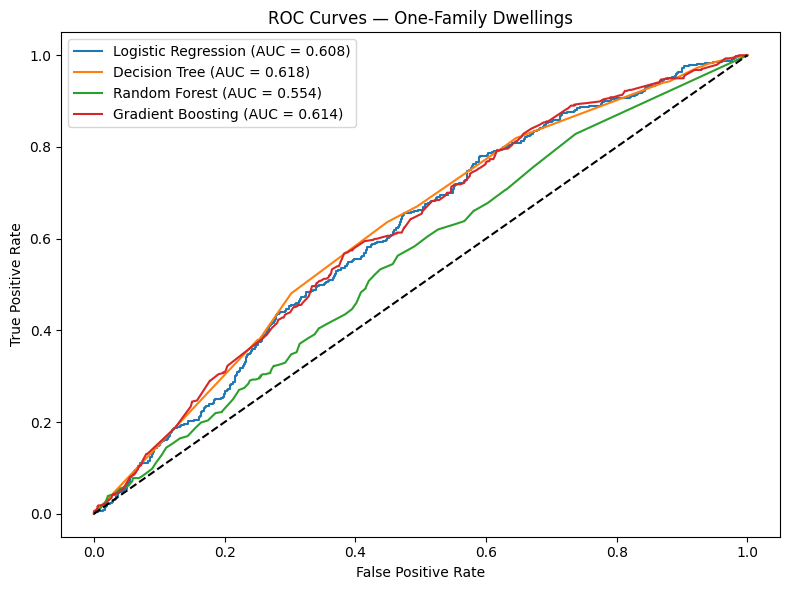

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

for name, model in trained.items():
    if name == 'Logistic Regression':
        probs = model.predict_proba(X_test_scaled)[:, 1]
    else:
        probs = model.predict_proba(X_test)[:, 1]

    fpr, tpr, _ = roc_curve(y_test, probs)
    auc = roc_auc_score(y_test, probs)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0,1],[0,1],'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves — One-Family Dwellings')
plt.legend()
plt.tight_layout()
plt.show()

Step 9 — Confusion Matrix & Classification Report

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

for name, model in trained.items():
    if name == 'Logistic Regression':
        preds = model.predict(X_test_scaled)
    else:
        preds = model.predict(X_test)

    print(f"\n{'='*40}")
    print(f"  {name}")
    print(f"{'='*40}")
    print(classification_report(y_test, preds, target_names=['Low','High']))


  Logistic Regression
              precision    recall  f1-score   support

         Low       0.82      0.53      0.64      1312
        High       0.32      0.66      0.43       437

    accuracy                           0.56      1749
   macro avg       0.57      0.59      0.53      1749
weighted avg       0.69      0.56      0.59      1749


  Decision Tree
              precision    recall  f1-score   support

         Low       0.82      0.55      0.66      1312
        High       0.32      0.64      0.43       437

    accuracy                           0.57      1749
   macro avg       0.57      0.59      0.54      1749
weighted avg       0.70      0.57      0.60      1749


  Random Forest
              precision    recall  f1-score   support

         Low       0.76      0.75      0.75      1312
        High       0.28      0.30      0.29       437

    accuracy                           0.63      1749
   macro avg       0.52      0.52      0.52      1749
weighted avg     

Step 10 — Lift Analysis
This shows whether the model concentrates high-return properties in the top predicted deciles — key for your business interpretation.

   Decile  High_Return_Rate      Lift
0       1          0.285714  1.143511
1       2          0.268571  1.074900
2       3          0.268571  1.074900
3       4          0.274286  1.097771
4       5          0.325714  1.303602
5       6          0.224138  0.897065
6       7          0.262857  1.052030
7       8          0.234286  0.937679
8       9          0.160000  0.640366
9      10          0.194286  0.777587


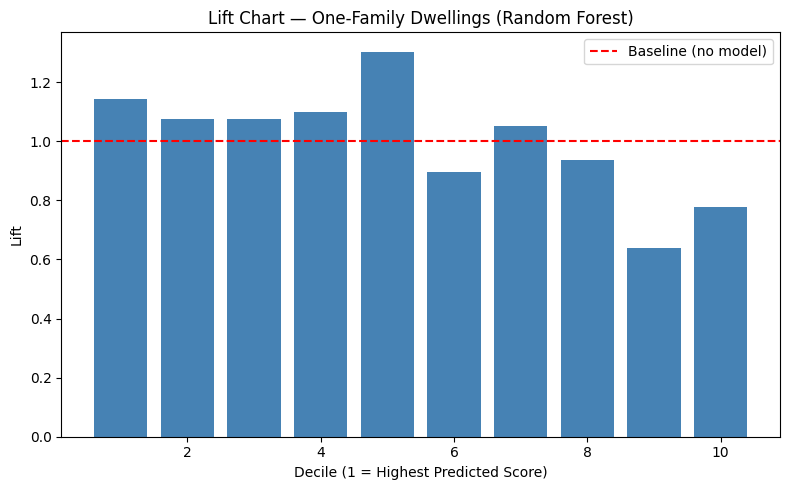

In [ ]:
import numpy as np

# Use your best model (e.g. Random Forest) — swap name as needed
best_model = trained['Random Forest']
probs = best_model.predict_proba(X_test)[:, 1]

lift_df = pd.DataFrame({'prob': probs, 'actual': y_test.values})
lift_df = lift_df.sort_values('prob', ascending=False).reset_index(drop=True)
lift_df['decile'] = pd.qcut(lift_df.index, 10, labels=False) + 1

lift_summary = lift_df.groupby('decile')['actual'].mean().reset_index()
lift_summary.columns = ['Decile', 'High_Return_Rate']
lift_summary['Lift'] = lift_summary['High_Return_Rate'] / lift_df['actual'].mean()

print(lift_summary)

# Plot
plt.figure(figsize=(8, 5))
plt.bar(lift_summary['Decile'], lift_summary['Lift'], color='steelblue')
plt.axhline(1, color='red', linestyle='--', label='Baseline (no model)')
plt.xlabel('Decile (1 = Highest Predicted Score)')
plt.ylabel('Lift')
plt.title('Lift Chart — One-Family Dwellings (Random Forest)')
plt.legend()
plt.tight_layout()
plt.show()

Step 11 — Feature Importance (Best Model)

                 Feature  Importance
1      DIST_TO_SUBWAY_KM    0.965948
0            crime_count    0.013921
6  BOROUGH_Staten Island    0.008324
5         BOROUGH_Queens    0.006851
2            NEAR_SUBWAY    0.001922
3       BOROUGH_Brooklyn    0.001888
4      BOROUGH_Manhattan    0.001145


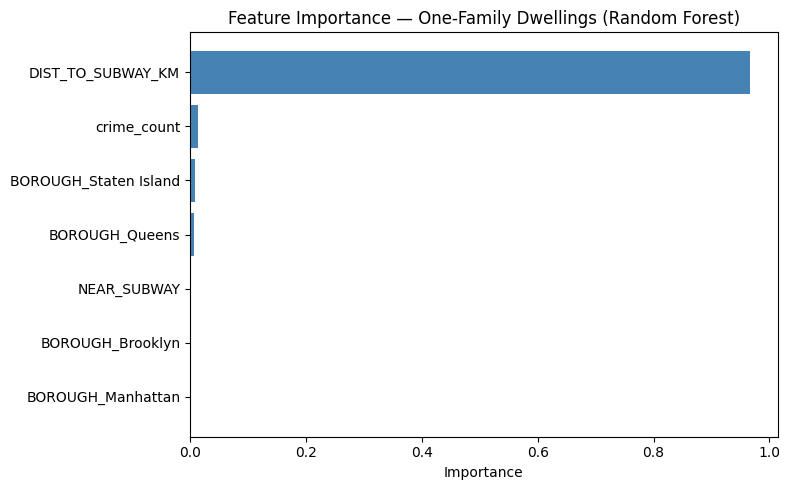

In [ ]:
best_model = trained['Random Forest']

importance_df = pd.DataFrame({
    'Feature'   : features,
    'Importance': best_model.feature_importances_
}).sort_values('Importance', ascending=False)

print(importance_df)

plt.figure(figsize=(8, 5))
plt.barh(importance_df['Feature'], importance_df['Importance'], color='steelblue')
plt.xlabel('Importance')
plt.title('Feature Importance — One-Family Dwellings (Random Forest)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Two family dwelling

Step 1 — Filter to Two-Family Segment

In [ ]:
two_fam = prop[prop['SEGMENT'] == 'Two-Family'].copy()
print("Two-Family properties:", two_fam.shape[0])
print(two_fam['HIGH_RETURN'].value_counts())

Two-Family properties: 5675
HIGH_RETURN
0    4256
1    1419
Name: count, dtype: int64


Step 2 — Descriptive Analytics (Two-Family Segment)


Annualized Return Summary — Two-Family:
count    5675.0000
mean        0.1807
std         0.2390
min        -0.4975
25%         0.0399
50%         0.1001
75%         0.2832
max         0.9999
Name: ANNUALIZED_RETURN, dtype: float64


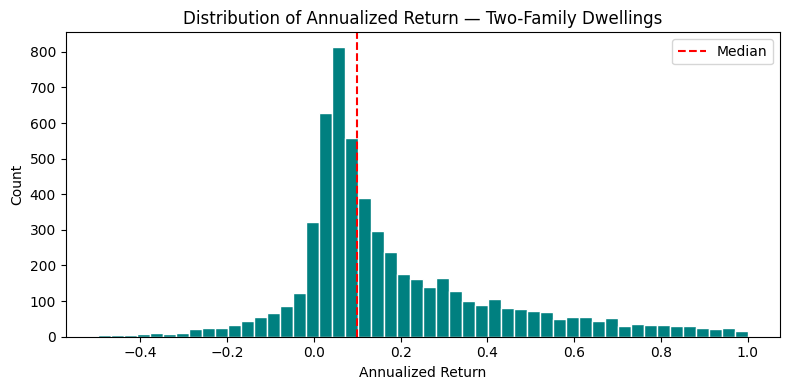

In [ ]:
# Distribution of annualized return
print("Annualized Return Summary — Two-Family:")
print(two_fam['ANNUALIZED_RETURN'].describe().round(4))

# Histogram
plt.figure(figsize=(8, 4))
plt.hist(two_fam['ANNUALIZED_RETURN'], bins=50, color='teal', edgecolor='white')
plt.axvline(two_fam['ANNUALIZED_RETURN'].median(), color='red', linestyle='--', label='Median')
plt.xlabel('Annualized Return')
plt.ylabel('Count')
plt.title('Distribution of Annualized Return — Two-Family Dwellings')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Target rate
print("High Return Target Rate — Two-Family:")
print(two_fam['HIGH_RETURN'].value_counts())
print(two_fam['HIGH_RETURN'].value_counts(normalize=True).round(3))

# NOTE:
# We expect approximately 25% of properties to be labeled HIGH_RETURN = 1
# because the threshold is set at the 75th percentile within this segment.
# Any significant deviation may indicate ties at the threshold boundary.

High Return Target Rate — Two-Family:
HIGH_RETURN
0    4256
1    1419
Name: count, dtype: int64
HIGH_RETURN
0    0.75
1    0.25
Name: proportion, dtype: float64


In [ ]:
# Average crime, subway distance, and return by borough
print("Feature Averages by Borough — Two-Family:")
two_fam.groupby('BOROUGH')[['crime_count', 'DIST_TO_SUBWAY_KM', 'ANNUALIZED_RETURN']].mean().round(4)

Feature Averages by Borough — Two-Family:


,crime_count,DIST_TO_SUBWAY_KM,ANNUALIZED_RETURN
BOROUGH,,,
Bronx,130358.0,0.8425,0.2094
Brooklyn,162384.0,0.5963,0.2015
Manhattan,136763.0,0.2987,0.0637
Queens,124471.0,1.8868,0.1771
Staten Island,24215.0,2.2378,0.1083


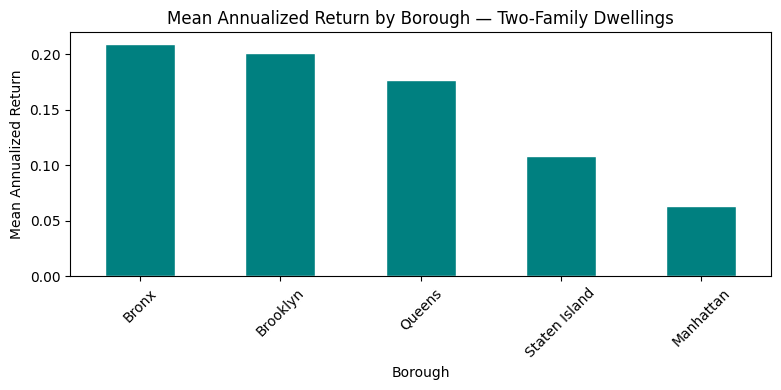

In [ ]:
# Return by borough (bar chart)
borough_summary = two_fam.groupby('BOROUGH')['ANNUALIZED_RETURN'].mean().sort_values(ascending=False)

plt.figure(figsize=(8, 4))
borough_summary.plot(kind='bar', color='teal', edgecolor='white')
plt.xlabel('Borough')
plt.ylabel('Mean Annualized Return')
plt.title('Mean Annualized Return by Borough — Two-Family Dwellings')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

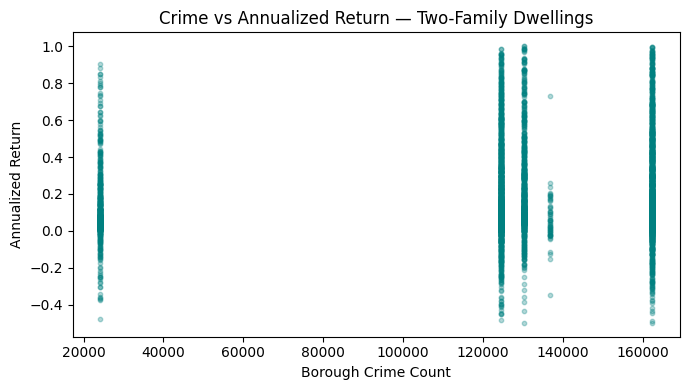

Correlation — Crime vs Return: 0.1237


In [ ]:
# Crime vs return scatter
plt.figure(figsize=(7, 4))
plt.scatter(two_fam['crime_count'], two_fam['ANNUALIZED_RETURN'], alpha=0.3, color='teal', s=10)
plt.xlabel('Borough Crime Count')
plt.ylabel('Annualized Return')
plt.title('Crime vs Annualized Return — Two-Family Dwellings')
plt.tight_layout()
plt.show()

print("Correlation — Crime vs Return:", two_fam[['crime_count','ANNUALIZED_RETURN']].corr().iloc[0,1].round(4))

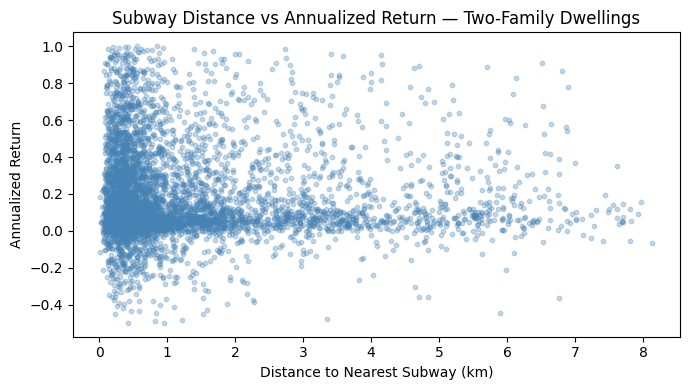

Correlation — Subway Distance vs Return: -0.017


In [ ]:
# Subway distance vs return scatter
plt.figure(figsize=(7, 4))
plt.scatter(two_fam['DIST_TO_SUBWAY_KM'], two_fam['ANNUALIZED_RETURN'], alpha=0.3, color='steelblue', s=10)
plt.xlabel('Distance to Nearest Subway (km)')
plt.ylabel('Annualized Return')
plt.title('Subway Distance vs Annualized Return — Two-Family Dwellings')
plt.tight_layout()
plt.show()

print("Correlation — Subway Distance vs Return:", two_fam[['DIST_TO_SUBWAY_KM','ANNUALIZED_RETURN']].corr().iloc[0,1].round(4))

Step 3 — Hypotheses
Based on the descriptive analysis above, we state the following hypotheses for Two-Family Dwellings before running any models:

H1 — Crime: Properties in higher-crime boroughs are less likely to achieve above-threshold appreciation. Two-family homes are often owner-occupied with a rental unit, making buyers sensitive to neighborhood safety.

H2 — Subway Access: Properties closer to subway stations are more likely to appreciate strongly, due to higher rental demand from tenants who rely on public transit.

H3 — Borough Effects: Two-family properties in Brooklyn and Queens are expected to outperform those in other boroughs, driven by population growth, gentrification, and strong rental markets in those areas.

H4 — Segment Behavior: The drivers of appreciation for two-family homes will differ from one-family homes because rental income potential adds an additional layer of value not present in purely owner-occupied properties.

Step 4 — Select Features & Check for Missingness


In [ ]:
features_2f = ['crime_count', 'DIST_TO_SUBWAY_KM', 'NEAR_SUBWAY']
target_2f   = 'HIGH_RETURN'

# Check missingness
print(two_fam[features_2f + [target_2f]].isnull().sum())

# Drop any rows with missing values in these columns
two_fam = two_fam.dropna(subset=features_2f + [target_2f])
print("After dropping nulls:", two_fam.shape[0])

crime_count          0
DIST_TO_SUBWAY_KM    0
NEAR_SUBWAY          0
HIGH_RETURN          0
dtype: int64
After dropping nulls: 5675


Step 5 — Encode Borough (Categorical → Numeric)

In [ ]:
two_fam = pd.get_dummies(two_fam, columns=['BOROUGH'], drop_first=True)

borough_dummies_2f = [c for c in two_fam.columns if c.startswith('BOROUGH_')]
features_2f = ['crime_count', 'DIST_TO_SUBWAY_KM', 'NEAR_SUBWAY'] + borough_dummies_2f

print("Features used:", features_2f)

Features used: ['crime_count', 'DIST_TO_SUBWAY_KM', 'NEAR_SUBWAY', 'BOROUGH_Brooklyn', 'BOROUGH_Manhattan', 'BOROUGH_Queens', 'BOROUGH_Staten Island']


Step 6 — Train / Test Split

In [ ]:
from sklearn.model_selection import train_test_split

X_2f = two_fam[features_2f]
y_2f = two_fam[target_2f]

X_train_2f, X_test_2f, y_train_2f, y_test_2f = train_test_split(
    X_2f, y_2f, test_size=0.2, random_state=42, stratify=y_2f
)

print("Train size:", X_train_2f.shape[0])
print("Test size :", X_test_2f.shape[0])

Train size: 4540
Test size : 1135


Step 7 — Scale Features (Required for Logistic Regression)

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler_2f = StandardScaler()
X_train_2f_scaled = scaler_2f.fit_transform(X_train_2f)
X_test_2f_scaled  = scaler_2f.transform(X_test_2f)

Step 8 — Train 4 Models

In [ ]:
from sklearn.linear_model  import LogisticRegression
from sklearn.tree          import DecisionTreeClassifier
from sklearn.ensemble      import RandomForestClassifier, GradientBoostingClassifier

models_2f = {
    'Logistic Regression' : LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    'Decision Tree'       : DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42),
    'Random Forest'       : RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42),
    'Gradient Boosting'   : GradientBoostingClassifier(n_estimators=100, random_state=42),
}

trained_2f = {}
for name, model in models_2f.items():
    if name == 'Logistic Regression':
        model.fit(X_train_2f_scaled, y_train_2f)
    else:
        model.fit(X_train_2f, y_train_2f)
    trained_2f[name] = model
    print(f"{name} trained.")

Logistic Regression trained.
Decision Tree trained.
Random Forest trained.
Gradient Boosting trained.



Step 9 — ROC Curves & AUC

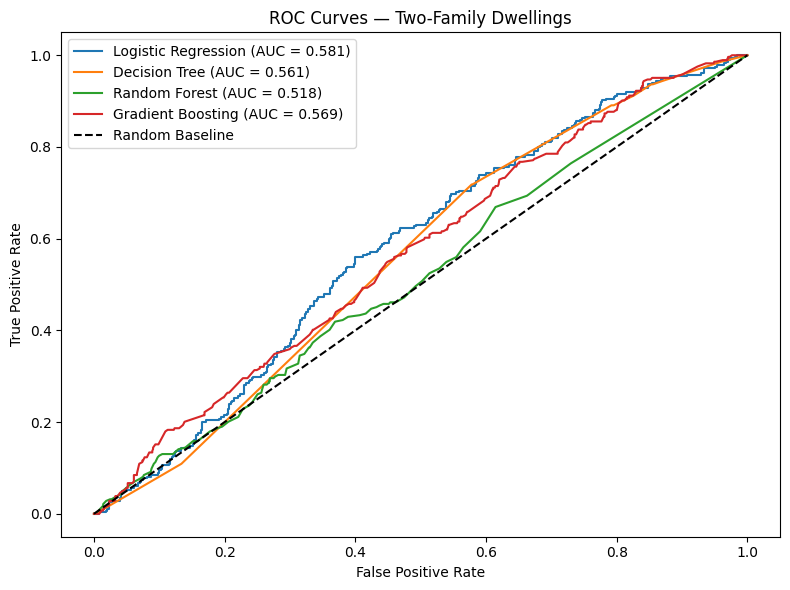


AUC Summary — Two-Family Dwellings:
  Logistic Regression       AUC = 0.581
  Gradient Boosting         AUC = 0.569
  Decision Tree             AUC = 0.561
  Random Forest             AUC = 0.518


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(8, 6))

auc_results_2f = {}

for name, model in trained_2f.items():
    if name == 'Logistic Regression':
        probs = model.predict_proba(X_test_2f_scaled)[:, 1]
    else:
        probs = model.predict_proba(X_test_2f)[:, 1]

    fpr, tpr, _ = roc_curve(y_test_2f, probs)
    auc = roc_auc_score(y_test_2f, probs)
    auc_results_2f[name] = auc
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0,1],[0,1],'k--', label='Random Baseline')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves — Two-Family Dwellings')
plt.legend()
plt.tight_layout()
plt.show()

# AUC summary table
print("\nAUC Summary — Two-Family Dwellings:")
for name, auc in sorted(auc_results_2f.items(), key=lambda x: -x[1]):
    print(f"  {name:<25} AUC = {auc:.3f}")

Step 10 — Confusion Matrix & Classification Report

In [ ]:
from sklearn.metrics import classification_report

for name, model in trained_2f.items():
    if name == 'Logistic Regression':
        preds = model.predict(X_test_2f_scaled)
    else:
        preds = model.predict(X_test_2f)

    print(f"\n{'='*40}")
    print(f"  {name}")
    print(f"{'='*40}")
    print(classification_report(y_test_2f, preds, target_names=['Low Return', 'High Return']))


  Logistic Regression
              precision    recall  f1-score   support

  Low Return       0.82      0.36      0.50       851
 High Return       0.28      0.76      0.41       284

    accuracy                           0.46      1135
   macro avg       0.55      0.56      0.46      1135
weighted avg       0.68      0.46      0.48      1135


  Decision Tree
              precision    recall  f1-score   support

  Low Return       0.82      0.42      0.56       851
 High Return       0.29      0.72      0.42       284

    accuracy                           0.50      1135
   macro avg       0.56      0.57      0.49      1135
weighted avg       0.69      0.50      0.52      1135


  Random Forest
              precision    recall  f1-score   support

  Low Return       0.76      0.73      0.74       851
 High Return       0.26      0.29      0.28       284

    accuracy                           0.62      1135
   macro avg       0.51      0.51      0.51      1135
weighted avg     

Step 11 — Lift Analysis

Best model for Two-Family: Logistic Regression (AUC = 0.581)
 Decile  High_Return_Rate     Lift
      1          0.236842 0.946534
      2          0.292035 1.167113
      3          0.350877 1.402273
      4          0.380531 1.520784
      5          0.271930 1.086762
      6          0.230088 0.919544
      7          0.194690 0.778076
      8          0.245614 0.981591
      9          0.185841 0.742708
     10          0.114035 0.455739


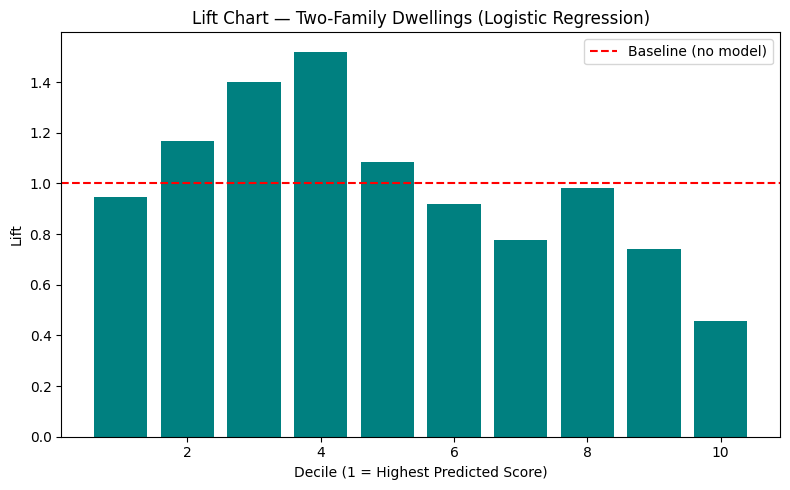

In [ ]:
import numpy as np

best_name_2f  = max(auc_results_2f, key=auc_results_2f.get)
best_model_2f = trained_2f[best_name_2f]
print(f"Best model for Two-Family: {best_name_2f} (AUC = {auc_results_2f[best_name_2f]:.3f})")

if best_name_2f == 'Logistic Regression':
    probs_2f = best_model_2f.predict_proba(X_test_2f_scaled)[:, 1]
else:
    probs_2f = best_model_2f.predict_proba(X_test_2f)[:, 1]

lift_df_2f = pd.DataFrame({'prob': probs_2f, 'actual': y_test_2f.values})
lift_df_2f = lift_df_2f.sort_values('prob', ascending=False).reset_index(drop=True)
lift_df_2f['decile'] = pd.qcut(lift_df_2f.index, 10, labels=False) + 1

lift_summary_2f = lift_df_2f.groupby('decile')['actual'].mean().reset_index()
lift_summary_2f.columns = ['Decile', 'High_Return_Rate']
lift_summary_2f['Lift'] = lift_summary_2f['High_Return_Rate'] / lift_df_2f['actual'].mean()

print(lift_summary_2f.to_string(index=False))

plt.figure(figsize=(8, 5))
plt.bar(lift_summary_2f['Decile'], lift_summary_2f['Lift'], color='teal')
plt.axhline(1, color='red', linestyle='--', label='Baseline (no model)')
plt.xlabel('Decile (1 = Highest Predicted Score)')
plt.ylabel('Lift')
plt.title(f'Lift Chart — Two-Family Dwellings ({best_name_2f})')
plt.legend()
plt.tight_layout()
plt.show()

Step 12 — Best Model Selection

In [ ]:
# Print AUC comparison
print("Model Comparison — Two-Family Dwellings:")
print(f"{'Model':<25} {'AUC':>6}")
print("-" * 33)
for name, auc in sorted(auc_results_2f.items(), key=lambda x: -x[1]):
    marker = " ← SELECTED" if name == best_name_2f else ""
    print(f"{name:<25} {auc:>6.3f}{marker}")

# NOTE:
# The best model is selected automatically based on highest AUC.
# AUC measures the model's ability to distinguish high-return properties
# from low-return ones across all possible classification thresholds.
# A higher AUC means the model is better at ranking properties correctly.

Model Comparison — Two-Family Dwellings:
Model                        AUC
---------------------------------
Logistic Regression        0.581 ← SELECTED
Gradient Boosting          0.569
Decision Tree              0.561
Random Forest              0.518


Step 13 — Feature Importance (Best Model)

Feature Importance — Two-Family Dwellings (Logistic Regression):
              Feature  Importance
    BOROUGH_Manhattan    0.268370
BOROUGH_Staten Island    0.256665
          crime_count    0.201554
    DIST_TO_SUBWAY_KM    0.106365
       BOROUGH_Queens    0.070901
          NEAR_SUBWAY    0.062124
     BOROUGH_Brooklyn    0.038121


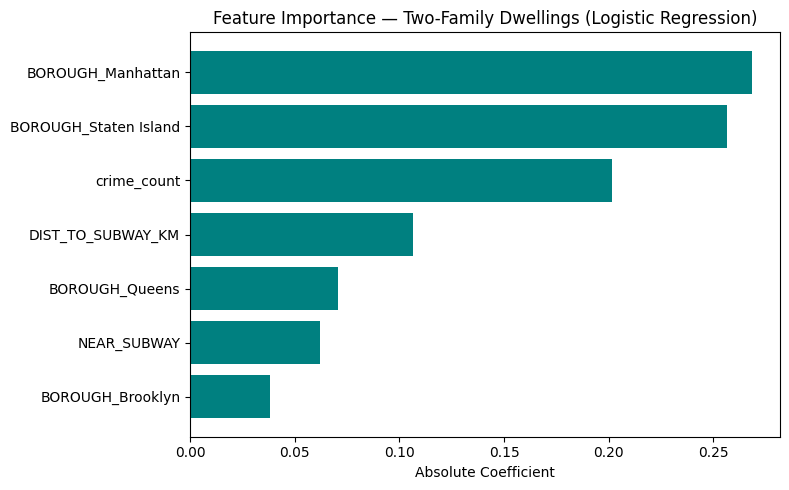

In [ ]:
if best_name_2f == 'Logistic Regression':
    importance_vals  = np.abs(best_model_2f.coef_[0])
    importance_label = 'Absolute Coefficient'
else:
    importance_vals  = best_model_2f.feature_importances_
    importance_label = 'Importance'

importance_df_2f = pd.DataFrame({
    'Feature'   : features_2f,
    'Importance': importance_vals
}).sort_values('Importance', ascending=False)

print(f"Feature Importance — Two-Family Dwellings ({best_name_2f}):")
print(importance_df_2f.to_string(index=False))

plt.figure(figsize=(8, 5))
plt.barh(importance_df_2f['Feature'], importance_df_2f['Importance'], color='teal')
plt.xlabel(importance_label)
plt.title(f'Feature Importance — Two-Family Dwellings ({best_name_2f})')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

Step 14 — Business Interpretation
What the model tells us about Two-Family Dwellings:

Two-family homes are heavily concentrated in Brooklyn, Queens, and the Bronx. They are often owner-occupied with a rental unit attached, meaning their appreciation is driven by both residential demand and rental income potential. This makes them behave differently from purely owner-occupied one-family homes.

Crime: If crime is a top predictor, it suggests that buyers and investors in this segment are sensitive to neighborhood safety — higher crime boroughs tend to see slower appreciation even for income-generating properties.

Subway Access: Strong subway access increases rental demand from tenants, which in turn supports price appreciation. Properties near transit corridors in Brooklyn and Queens have historically benefited from this effect.

Borough Effects: Borough dummies capturing areas like Brooklyn and Queens are expected to show strong positive importance, reflecting gentrification pressure and population-driven demand in those markets during the study period.

Who benefits from this model:

Investors evaluating two-family properties as buy-and-hold rental assets
Buyers assessing whether a two-family home in a given neighborhood is likely to appreciate relative to similar properties
Lenders evaluating collateral quality for multi-family residential mortgages
Urban planners tracking neighborhood-level residential value trends

##Co-op

In [ ]:
# ============================================================
# Co-op helper functions and imports
# ============================================================

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.neighbors import BallTree
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    roc_auc_score, accuracy_score, precision_score,
    recall_score, f1_score, classification_report
)


def clean_text(x):
    """Aggressive cleaner for matching income/neighborhood names."""
    if pd.isna(x):
        return np.nan
    x = str(x).upper().strip()
    x = re.sub(r"\([^)]*\)", "", x)  # remove parenthetical ranges like (59-79)
    x = x.replace("&", "AND")
    x = re.sub(r"[/\-]+", " ", x)
    x = re.sub(r"[^A-Z0-9 ]+", " ", x)
    x = re.sub(r"\s+", " ", x).strip()
    return x


def clean_key(x):
    """Cleaner for exact merge keys; keeps parenthetical subareas for DOF neighborhoods."""
    if pd.isna(x):
        return np.nan
    x = str(x).upper().strip()
    x = x.replace("&", "AND")
    x = re.sub(r"[/\-]+", " ", x)
    x = re.sub(r"[^A-Z0-9() ]+", " ", x)
    x = re.sub(r"\s+", " ", x).strip()
    return x


def clean_borough(x):
    x = clean_text(x)
    return {
        "1": "MANHATTAN", "2": "BRONX", "3": "BROOKLYN",
        "4": "QUEENS", "5": "STATEN ISLAND",
        "NEW YORK": "MANHATTAN", "MANHATTAN": "MANHATTAN",
        "BRONX": "BRONX", "BROOKLYN": "BROOKLYN",
        "KINGS": "BROOKLYN", "QUEENS": "QUEENS",
        "STATEN ISLAND": "STATEN ISLAND", "RICHMOND": "STATEN ISLAND"
    }.get(x, x)

In [ ]:
# ============================================================
# 1. Build Co-op neighborhood target and merge neighborhood factors
# ============================================================

# Co-op BBLs are often building-level rather than apartment-level, so this
# section uses neighborhood-level median price appreciation instead of BBL repeat sales.
base_df = housing_res.copy()
base_df.columns = base_df.columns.str.strip()

coop_sales = base_df[base_df["SEGMENT"] == "Co-op"].copy()
coop_sales["SALE DATE"] = pd.to_datetime(coop_sales["SALE DATE"], errors="coerce")
coop_sales["SALE_YEAR"] = coop_sales["SALE DATE"].dt.year
coop_sales["SALE PRICE"] = pd.to_numeric(coop_sales["SALE PRICE"], errors="coerce")
coop_sales = coop_sales.dropna(subset=["BOROUGH", "NEIGHBORHOOD", "SALE DATE", "SALE_YEAR", "SALE PRICE"])
coop_sales = coop_sales[coop_sales["SALE PRICE"] >= 100000].copy()

early_years = [2016, 2017, 2018]
late_years = [2023, 2024]
min_sales_per_period = 10

coop_sales["PERIOD"] = np.select(
    [coop_sales["SALE_YEAR"].isin(early_years), coop_sales["SALE_YEAR"].isin(late_years)],
    ["Early", "Late"],
    default=pd.NA
)

coop_neigh = (
    coop_sales.dropna(subset=["PERIOD"])
    .groupby(["BOROUGH", "NEIGHBORHOOD", "PERIOD"], as_index=False)
    .agg(median_price=("SALE PRICE", "median"), sales_count=("SALE PRICE", "count"))
)

coop_model = coop_neigh.pivot_table(
    index=["BOROUGH", "NEIGHBORHOOD"],
    columns="PERIOD",
    values=["median_price", "sales_count"]
).reset_index()

coop_model.columns = [
    "_".join([str(x) for x in col if x != ""]).strip("_") if isinstance(col, tuple) else col
    for col in coop_model.columns
]

coop_model = coop_model.rename(columns={
    "median_price_Early": "EARLY_PRICE",
    "median_price_Late": "LATE_PRICE",
    "sales_count_Early": "EARLY_SALES_COUNT",
    "sales_count_Late": "LATE_SALES_COUNT"
})

coop_model = coop_model.dropna(subset=["EARLY_PRICE", "LATE_PRICE"]).copy()
coop_model = coop_model[
    (coop_model["EARLY_SALES_COUNT"] >= min_sales_per_period) &
    (coop_model["LATE_SALES_COUNT"] >= min_sales_per_period)
].copy()

holding_years = np.mean(late_years) - np.mean(early_years)
coop_model["LOG_ANNUALIZED_RETURN"] = np.log(coop_model["LATE_PRICE"] / coop_model["EARLY_PRICE"]) / holding_years
coop_model["ANNUALIZED_RETURN"] = np.expm1(coop_model["LOG_ANNUALIZED_RETURN"])

threshold_coop = coop_model["LOG_ANNUALIZED_RETURN"].quantile(0.75)
coop_model["HIGH_RETURN"] = (coop_model["LOG_ANNUALIZED_RETURN"] >= threshold_coop).astype(int)
coop_model["BOROUGH_KEY"] = coop_model["BOROUGH"].apply(clean_borough)
coop_model["NEIGHBORHOOD_KEY"] = coop_model["NEIGHBORHOOD"].apply(clean_key)

# Neighborhood center coordinates from sale records.
center_source = coop_sales.copy()
center_source["BOROUGH_KEY"] = center_source["BOROUGH"].apply(clean_borough)
center_source["NEIGHBORHOOD_KEY"] = center_source["NEIGHBORHOOD"].apply(clean_key)
center_source["Latitude"] = pd.to_numeric(center_source["Latitude"], errors="coerce")
center_source["Longitude"] = pd.to_numeric(center_source["Longitude"], errors="coerce")

neighborhood_centers = (
    center_source.dropna(subset=["Latitude", "Longitude"])
    .groupby(["BOROUGH_KEY", "NEIGHBORHOOD_KEY"], as_index=False)
    .agg(CENTER_LAT=("Latitude", "mean"), CENTER_LON=("Longitude", "mean"))
)

coop_model = coop_model.merge(neighborhood_centers, on=["BOROUGH_KEY", "NEIGHBORHOOD_KEY"], how="left")
coop_model = coop_model.dropna(subset=["CENTER_LAT", "CENTER_LON"]).copy()

# Subway features.
subway_clean = mta.copy()
subway_clean["LATITUDE"] = pd.to_numeric(subway_clean["LATITUDE"], errors="coerce")
subway_clean["LONGITUDE"] = pd.to_numeric(subway_clean["LONGITUDE"], errors="coerce")
subway_clean = subway_clean.dropna(subset=["LATITUDE", "LONGITUDE"]).copy()

subway_tree = BallTree(np.radians(subway_clean[["LATITUDE", "LONGITUDE"]].to_numpy()), metric="haversine")
dist_rad, _ = subway_tree.query(np.radians(coop_model[["CENTER_LAT", "CENTER_LON"]].to_numpy()), k=1)
coop_model["DIST_TO_SUBWAY_KM"] = dist_rad.flatten() * 6371
coop_model["NEAR_SUBWAY"] = (coop_model["DIST_TO_SUBWAY_KM"] <= 0.8).astype(int)

# Crime within 1 km of each neighborhood center.
lat_candidates = ["Latitude", "LATITUDE", "Lat", "LAT"]
lon_candidates = ["Longitude", "LONGITUDE", "Lon", "LON"]
nypd_lat_col = next((c for c in lat_candidates if c in nypd.columns), None)
nypd_lon_col = next((c for c in lon_candidates if c in nypd.columns), None)

if nypd_lat_col is None or nypd_lon_col is None:
    raise ValueError("NYPD latitude/longitude columns were not found.")

nypd_geo = nypd[["BORO_NM", nypd_lat_col, nypd_lon_col]].copy()
nypd_geo[nypd_lat_col] = pd.to_numeric(nypd_geo[nypd_lat_col], errors="coerce")
nypd_geo[nypd_lon_col] = pd.to_numeric(nypd_geo[nypd_lon_col], errors="coerce")
nypd_geo["BOROUGH_KEY"] = nypd_geo["BORO_NM"].apply(clean_borough)
nypd_geo = nypd_geo.dropna(subset=["BOROUGH_KEY", nypd_lat_col, nypd_lon_col]).copy()

crime_radius_km = 1.0
crime_counts = []

for boro in coop_model["BOROUGH_KEY"].dropna().unique():
    centers_boro = coop_model[coop_model["BOROUGH_KEY"] == boro].copy()
    crimes_boro = nypd_geo[nypd_geo["BOROUGH_KEY"] == boro].copy()
    if centers_boro.empty or crimes_boro.empty:
        continue

    crime_tree = BallTree(np.radians(crimes_boro[[nypd_lat_col, nypd_lon_col]].to_numpy()), metric="haversine")
    counts = crime_tree.query_radius(
        np.radians(centers_boro[["CENTER_LAT", "CENTER_LON"]].to_numpy()),
        r=crime_radius_km / 6371,
        count_only=True
    )
    crime_counts.append(centers_boro[["BOROUGH_KEY", "NEIGHBORHOOD_KEY"]].assign(CRIME_COUNT_1KM=counts))

crime_counts = pd.concat(crime_counts, ignore_index=True)
coop_model = coop_model.merge(crime_counts, on=["BOROUGH_KEY", "NEIGHBORHOOD_KEY"], how="left")
coop_model["CRIME_COUNT_1KM"] = coop_model["CRIME_COUNT_1KM"].fillna(0).astype(int)
coop_model["LOG_CRIME_COUNT_1KM"] = np.log1p(coop_model["CRIME_COUNT_1KM"])

# Income feature.
income_area_crosswalk = {'ALPHABET CITY': 'LOWER EAST SIDE', 'EAST VILLAGE': 'LOWER EAST SIDE', 'CHINATOWN': 'LOWER EAST SIDE', 'FINANCIAL': 'BATTERY PARK TRIBECA', 'TRIBECA': 'BATTERY PARK TRIBECA', 'CIVIC CENTER': 'BATTERY PARK TRIBECA', 'SOUTHBRIDGE': 'BATTERY PARK TRIBECA', 'CHELSEA': 'CHELSEA CLINTON', 'CLINTON': 'CHELSEA CLINTON', 'MIDTOWN WEST': 'CHELSEA CLINTON', 'JAVITS CENTER': 'CHELSEA CLINTON', 'FASHION': 'CHELSEA CLINTON', 'MIDTOWN EAST': 'MIDTOWN BUSINESS DISTRICT', 'GRAMERCY': 'MURRAY HILL STUYVESANT', 'FLATIRON': 'MURRAY HILL STUYVESANT', 'KIPS BAY': 'MURRAY HILL STUYVESANT', 'GREENWICH VILLAGE CENTRAL': 'GREENWICH VILLAGE', 'GREENWICH VILLAGE WEST': 'GREENWICH VILLAGE', 'SOHO': 'GREENWICH VILLAGE', 'UPPER EAST SIDE': 'UPPER EAST SIDE', 'UPPER WEST SIDE': 'UPPER WEST SIDE', 'ROOSEVELT ISLAND': 'UPPER EAST SIDE', 'HARLEM CENTRAL': 'CENTRAL HARLEM', 'HARLEM EAST': 'EAST HARLEM', 'HARLEM UPPER': 'CENTRAL HARLEM', 'HARLEM WEST': 'CENTRAL HARLEM', 'INWOOD': 'WASHINGTON HEIGHTS', 'WASHINGTON HEIGHTS LOWER': 'WASHINGTON HEIGHTS', 'WASHINGTON HEIGHTS UPPER': 'WASHINGTON HEIGHTS', 'CASTLE HILL UNIONPORT': 'UNIONPORT SOUNDVIEW', 'SOUNDVIEW': 'UNIONPORT SOUNDVIEW', 'PARKCHESTER': 'UNIONPORT SOUNDVIEW', 'WESTCHESTER': 'UNIONPORT SOUNDVIEW', 'BEDFORD PARK NORWOOD': 'BEDFORD PARK', 'FIELDSTON': 'RIVERDALE', 'HIGHBRIDGE MORRIS HEIGHTS': 'CONCOURSE HIGHBRIDGE', 'MOTT HAVEN PORT MORRIS': 'MOTT HAVEN', 'BAYCHESTER': 'WILLIAMSBRIDGE', 'PELHAM PARKWAY NORTH': 'PELHAM PARKWAY', 'PELHAM PARKWAY SOUTH': 'PELHAM PARKWAY', 'SCHUYLERVILLE PELHAM BAY': 'THROGS NECK', 'MORRISANIA LONGWOOD': 'MORRISANIA', 'CROTONA PARK': 'MORRISANIA', 'BATHGATE': 'EAST TREMONT', 'FORDHAM': 'UNIVERSITY HEIGHTS', 'WOODLAWN': 'WILLIAMSBRIDGE', 'VAN CORTLANDT PARK': 'RIVERDALE', 'BROOKLYN HEIGHTS': 'FORT GREENE BROOKLYN HTS', 'DOWNTOWN FULTON FERRY': 'FORT GREENE BROOKLYN HTS', 'DOWNTOWN FULTON MALL': 'FORT GREENE BROOKLYN HTS', 'DOWNTOWN METROTECH': 'FORT GREENE BROOKLYN HTS', 'BOERUM HILL': 'FORT GREENE BROOKLYN HTS', 'COBBLE HILL': 'FORT GREENE BROOKLYN HTS', 'CARROLL GARDENS': 'FORT GREENE BROOKLYN HTS', 'FORT GREENE': 'FORT GREENE BROOKLYN HTS', 'CLINTON HILL': 'FORT GREENE BROOKLYN HTS', 'GOWANUS': 'PARK SLOPE', 'PARK SLOPE SOUTH': 'PARK SLOPE', 'PROSPECT HEIGHTS': 'PARK SLOPE', 'WINDSOR TERRACE': 'PARK SLOPE', 'WILLIAMSBURG CENTRAL': 'WILLIAMSBURG GREENPOINT', 'WILLIAMSBURG EAST': 'WILLIAMSBURG GREENPOINT', 'WILLIAMSBURG NORTH': 'WILLIAMSBURG GREENPOINT', 'WILLIAMSBURG SOUTH': 'WILLIAMSBURG GREENPOINT', 'GREENPOINT': 'WILLIAMSBURG GREENPOINT', 'OCEAN HILL': 'BEDFORD STUYVESANT', 'CYPRESS HILLS': 'EAST NEW YORK', 'CROWN HEIGHTS': 'CROWN HEIGHTS NORTH', 'OCEAN PARKWAY NORTH': 'FLATBUSH MIDWOOD', 'OCEAN PARKWAY SOUTH': 'FLATBUSH MIDWOOD', 'FLATBUSH CENTRAL': 'FLATBUSH MIDWOOD', 'FLATBUSH EAST': 'FLATBUSH MIDWOOD', 'FLATBUSH LEFFERTS GARDEN': 'FLATBUSH MIDWOOD', 'FLATBUSH NORTH': 'FLATBUSH MIDWOOD', 'KENSINGTON': 'FLATBUSH MIDWOOD', 'MIDWOOD': 'FLATBUSH MIDWOOD', 'BATH BEACH': 'BAY RIDGE', 'DYKER HEIGHTS': 'BOROUGH PARK', 'BRIGHTON BEACH': 'CONEY ISLAND', 'BERGEN BEACH': 'SHEEPSHEAD BAY', 'FLATLANDS': 'SHEEPSHEAD BAY', 'OLD MILL BASIN': 'SHEEPSHEAD BAY', 'RED HOOK': 'PARK SLOPE', 'ASTORIA': 'ASTORIA', 'LONG ISLAND CITY': 'ASTORIA', 'SUNNYSIDE': 'SUNNYSIDE WOODSIDE', 'WOODSIDE': 'SUNNYSIDE WOODSIDE', 'ELMHURST': 'ELMHURST CORONA', 'CORONA': 'ELMHURST CORONA', 'EAST ELMHURST': 'ELMHURST CORONA', 'RIDGEWOOD': 'RIDGEWOOD GLENDALE', 'GLENDALE': 'RIDGEWOOD GLENDALE', 'FOREST HILLS': 'REGO PARK FOREST HILLS', 'REGO PARK': 'REGO PARK FOREST HILLS', 'KEW GARDENS': 'REGO PARK FOREST HILLS', 'FLUSHING NORTH': 'FLUSHING', 'FLUSHING SOUTH': 'FLUSHING', 'FLUSHING MEADOW PARK': 'FLUSHING', 'FRESH MEADOWS': 'FRESH MEADOWS BRIARWOOD', 'BRIARWOOD': 'FRESH MEADOWS BRIARWOOD', 'HILLCREST': 'FRESH MEADOWS BRIARWOOD', 'RICHMOND HILL': 'WOODHAVEN', 'BEECHHURST': 'BAYSIDE', 'WHITESTONE': 'BAYSIDE', 'DOUGLASTON': 'BAYSIDE', 'OAKLAND GARDENS': 'BAYSIDE', 'JAMAICA ESTATES': 'JAMAICA ST ALBANS', 'JAMAICA HILLS': 'JAMAICA ST ALBANS', 'HOLLIS': 'JAMAICA ST ALBANS', 'HOLLIS HILLS': 'QUEENS VILLAGE', 'HOLLISWOOD': 'QUEENS VILLAGE', 'SPRINGFIELD GARDENS': 'QUEENS VILLAGE', 'FAR ROCKAWAY': 'THE ROCKAWAYS', 'ROCKAWAY PARK': 'THE ROCKAWAYS', 'BELLE HARBOR': 'THE ROCKAWAYS', 'FLORAL PARK': 'QUEENS VILLAGE', 'GLEN OAKS': 'QUEENS VILLAGE', 'ST GEORGE': 'ST GEORGE', 'GRYMES HILL': 'ST GEORGE', 'CONCORD FOX HILLS': 'ST GEORGE', 'WEST NEW BRIGHTON': 'ST GEORGE', 'ROSEBANK': 'ST GEORGE', 'CLOVE LAKES': 'ST GEORGE', 'ARROCHAR SHORE ACRES': 'SOUTH BEACH', 'DONGAN HILLS': 'SOUTH BEACH', 'GRANT CITY': 'SOUTH BEACH', 'GREAT KILLS': 'TOTTENVILLE', 'GREAT KILLS BAY TERRACE': 'TOTTENVILLE'}

income_lookup = dict(zip(income_summary["NEIGHBORHOOD"].apply(clean_text), income_summary["Income"]))

def get_income_area(neighborhood_name):
    key = clean_text(neighborhood_name)
    if key in income_lookup:
        return key
    mapped_key = income_area_crosswalk.get(key)
    if mapped_key in income_lookup:
        return mapped_key
    return np.nan

coop_model["INCOME_AREA_KEY"] = coop_model["NEIGHBORHOOD"].apply(get_income_area)
coop_model["MEDIAN_INCOME_2015"] = coop_model["INCOME_AREA_KEY"].map(income_lookup)

factor_cols = ["LOG_CRIME_COUNT_1KM", "MEDIAN_INCOME_2015", "DIST_TO_SUBWAY_KM", "NEAR_SUBWAY"]

print("Co-op sale rows used:", coop_sales.shape[0])
print("Co-op neighborhoods in final model:", coop_model.shape[0])
print("High-return threshold, approx annual return:", round(np.expm1(threshold_coop), 4))
print("\nTarget split:")
print(coop_model["HIGH_RETURN"].value_counts())
print(coop_model["HIGH_RETURN"].value_counts(normalize=True).round(3))
print("\nFeature coverage:")
print((coop_model[factor_cols].notna().mean() * 100).round(1).astype(str) + "%")
print("\nRows without income match:")
print(coop_model.loc[coop_model["MEDIAN_INCOME_2015"].isna(), ["BOROUGH", "NEIGHBORHOOD"]].head(20))

display(coop_model[[
    "BOROUGH", "NEIGHBORHOOD", "HIGH_RETURN", "ANNUALIZED_RETURN",
    "CRIME_COUNT_1KM", "MEDIAN_INCOME_2015", "DIST_TO_SUBWAY_KM", "NEAR_SUBWAY"
]].head(10))

Co-op sale rows used: 121205
Co-op neighborhoods in final model: 137
High-return threshold, approx annual return: 0.0366

Target split:
HIGH_RETURN
0    102
1     35
Name: count, dtype: int64
HIGH_RETURN
0    0.745
1    0.255
Name: proportion, dtype: float64

Feature coverage:
LOG_CRIME_COUNT_1KM    100.0%
MEDIAN_INCOME_2015      86.9%
DIST_TO_SUBWAY_KM      100.0%
NEAR_SUBWAY            100.0%
dtype: object

Rows without income match:
           BOROUGH              NEIGHBORHOOD
2            Bronx                 BRONXDALE
5            Bronx  KINGSBRIDGE HTS/UNIV HTS
6            Bronx   KINGSBRIDGE/JEROME PARK
7            Bronx         MELROSE/CONCOURSE
8            Bronx      MORRIS PARK/VAN NEST
38        Brooklyn                 GRAVESEND
40        Brooklyn                   MADISON
41        Brooklyn               MARINE PARK
72       Manhattan          MANHATTAN VALLEY
73       Manhattan               MIDTOWN CBD
76       Manhattan       MORNINGSIDE HEIGHTS
77       Manhattan  

,BOROUGH,NEIGHBORHOOD,HIGH_RETURN,ANNUALIZED_RETURN,CRIME_COUNT_1KM,MEDIAN_INCOME_2015,DIST_TO_SUBWAY_KM,NEAR_SUBWAY
0,Bronx,BAYCHESTER,1,0.046125,2417,58665.97478,0.191784,1
1,Bronx,BEDFORD PARK/NORWOOD,0,0.014771,5117,39470.26813,0.340738,1
2,Bronx,BRONXDALE,0,0.027187,4050,NaN,0.276469,1
3,Bronx,FIELDSTON,0,-0.005106,455,76268.73313,0.661083,1
4,Bronx,FORDHAM,1,0.042258,11129,29884.15491,0.153185,1
5,Bronx,KINGSBRIDGE HTS/UNIV HTS,0,0.009857,6245,NaN,0.547044,1
6,Bronx,KINGSBRIDGE/JEROME PARK,1,0.059560,3314,NaN,0.336609,1
7,Bronx,MELROSE/CONCOURSE,0,0.035602,8031,NaN,0.311560,1
8,Bronx,MORRIS PARK/VAN NEST,1,0.064366,2965,NaN,0.436855,1
9,Bronx,MORRISANIA/LONGWOOD,0,0.017788,9450,29719.79330,0.130988,1


In [ ]:
# ============================================================
# 2. Train and compare Co-op classification models
# ============================================================

target_coop = "HIGH_RETURN"
numeric_features = ["LOG_CRIME_COUNT_1KM", "MEDIAN_INCOME_2015", "DIST_TO_SUBWAY_KM", "NEAR_SUBWAY"]
categorical_features = ["BOROUGH"]
features_coop = numeric_features + categorical_features

coop_model_ready = coop_model.dropna(subset=[target_coop] + categorical_features).copy()
X_coop = coop_model_ready[features_coop]
y_coop = coop_model_ready[target_coop]

X_train_coop, X_test_coop, y_train_coop, y_test_coop = train_test_split(
    X_coop, y_coop, test_size=0.2, random_state=42, stratify=y_coop
)

try:
    ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    ohe = OneHotEncoder(handle_unknown="ignore", sparse=False)

preprocessor = ColumnTransformer(transformers=[
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", ohe)
    ]), categorical_features)
])

models_coop = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=5, class_weight="balanced", random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, max_depth=2, random_state=42)
}

trained_models_coop = {}
results_coop = []

for name, model in models_coop.items():
    pipe = Pipeline([("preprocess", preprocessor), ("model", model)])
    pipe.fit(X_train_coop, y_train_coop)
    y_pred = pipe.predict(X_test_coop)
    y_prob = pipe.predict_proba(X_test_coop)[:, 1]
    trained_models_coop[name] = pipe
    results_coop.append({
        "Model": name,
        "AUC": roc_auc_score(y_test_coop, y_prob),
        "Accuracy": accuracy_score(y_test_coop, y_pred),
        "Precision": precision_score(y_test_coop, y_pred, zero_division=0),
        "Recall": recall_score(y_test_coop, y_pred, zero_division=0),
        "F1": f1_score(y_test_coop, y_pred, zero_division=0)
    })

results_coop_df = pd.DataFrame(results_coop).sort_values("AUC", ascending=False)
display(results_coop_df)

best_model_name = results_coop_df.iloc[0]["Model"]
best_model_coop = trained_models_coop[best_model_name]
print("Best Co-op model by AUC:", best_model_name)

for name, model in trained_models_coop.items():
    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)
    print(classification_report(
        y_test_coop,
        model.predict(X_test_coop),
        target_names=["Lower Return", "High Return"],
        zero_division=0
    ))

,Model,AUC,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.693878,0.642857,0.384615,0.714286,0.500000
2,Random Forest,0.564626,0.642857,0.285714,0.285714,0.285714
1,Decision Tree,0.523810,0.500000,0.266667,0.571429,0.363636
3,Gradient Boosting,0.459184,0.607143,0.250000,0.285714,0.266667


Best Co-op model by AUC: Logistic Regression

Logistic Regression
              precision    recall  f1-score   support

Lower Return       0.87      0.62      0.72        21
 High Return       0.38      0.71      0.50         7

    accuracy                           0.64        28
   macro avg       0.63      0.67      0.61        28
weighted avg       0.75      0.64      0.67        28


Decision Tree
              precision    recall  f1-score   support

Lower Return       0.77      0.48      0.59        21
 High Return       0.27      0.57      0.36         7

    accuracy                           0.50        28
   macro avg       0.52      0.52      0.48        28
weighted avg       0.64      0.50      0.53        28


Random Forest
              precision    recall  f1-score   support

Lower Return       0.76      0.76      0.76        21
 High Return       0.29      0.29      0.29         7

    accuracy                           0.64        28
   macro avg       0.52      0.5

Top predicted Co-op neighborhoods:


,BOROUGH,NEIGHBORHOOD,HIGH_RETURN,PRED_HIGH_RETURN,PRED_HIGH_RETURN_PROB,ANNUALIZED_RETURN,EARLY_PRICE,LATE_PRICE,EARLY_SALES_COUNT,LATE_SALES_COUNT,CRIME_COUNT_1KM,MEDIAN_INCOME_2015,DIST_TO_SUBWAY_KM,NEAR_SUBWAY
0,Queens,BELLE HARBOR,0,1,0.868,0.0235,257500.0,299500.0,21.0,10.0,163,64674.44228,1.289,0
1,Staten Island,CLOVE LAKES,0,1,0.848,0.0021,182500.0,185000.0,46.0,28.0,253,69061.53805,2.779,0
2,Staten Island,GRYMES HILL,0,1,0.807,0.0359,163000.0,205000.0,33.0,19.0,663,69061.53805,1.927,0
3,Queens,LITTLE NECK,0,1,0.792,0.0316,245000.0,300000.0,302.0,141.0,302,NaN,7.123,0
4,Staten Island,ROSEBANK,1,1,0.786,0.0450,199000.0,264900.0,36.0,18.0,1054,69061.53805,1.069,0
5,Staten Island,ARROCHAR-SHORE ACRES,0,1,0.783,-0.0271,275000.0,230000.0,15.0,15.0,370,91293.60930,1.449,0
6,Bronx,WOODLAWN,0,1,0.781,0.0138,150000.0,164000.0,73.0,55.0,1232,58665.97478,1.009,0
7,Queens,FLUSHING-SOUTH,0,1,0.772,0.0351,231718.5,290000.0,704.0,351.0,1393,62657.61403,1.634,0
8,Queens,GLENDALE,0,1,0.764,0.0314,222500.0,272000.0,152.0,69.0,850,76983.02647,0.834,0
9,Queens,BEECHHURST,0,1,0.763,0.0354,335000.0,420000.0,265.0,153.0,243,97902.67639,4.478,0


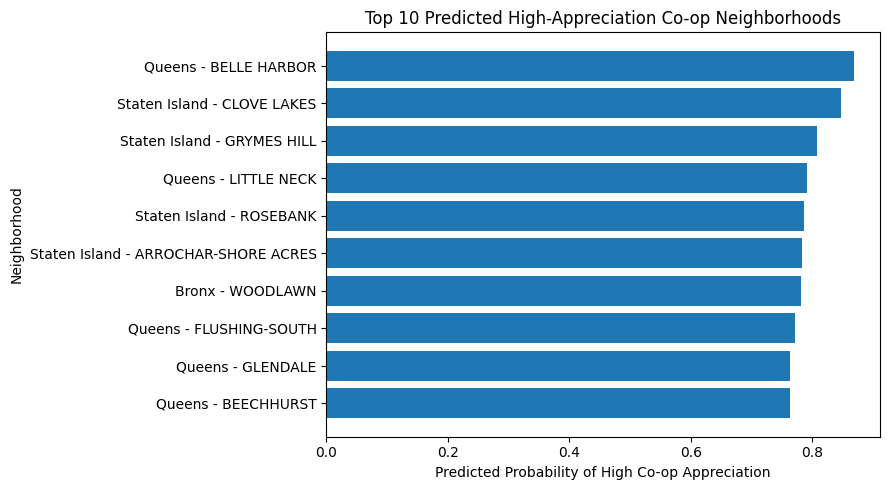

Lowest predicted Co-op neighborhoods:


,BOROUGH,NEIGHBORHOOD,HIGH_RETURN,PRED_HIGH_RETURN,PRED_HIGH_RETURN_PROB,ANNUALIZED_RETURN,EARLY_PRICE,LATE_PRICE,EARLY_SALES_COUNT,LATE_SALES_COUNT,CRIME_COUNT_1KM,MEDIAN_INCOME_2015,DIST_TO_SUBWAY_KM,NEAR_SUBWAY
122,Manhattan,CHELSEA,0,0,0.125,-0.0084,690000.0,653310.0,720.0,444.0,9092,126392.8471,0.208,1
123,Manhattan,KIPS BAY,0,0,0.119,0.0007,607250.0,610000.0,109.0,90.0,8117,132047.8753,0.589,1
124,Manhattan,MIDTOWN WEST,0,0,0.118,-0.0074,747800.0,712500.0,417.0,258.0,11299,126392.8471,0.116,1
125,Manhattan,CLINTON,0,0,0.113,0.0224,490000.0,566000.0,185.0,92.0,12939,126392.8471,0.415,1
126,Manhattan,GRAMERCY,0,0,0.112,-0.0001,750500.0,750000.0,798.0,441.0,10138,132047.8753,0.317,1
127,Manhattan,FLATIRON,0,0,0.108,-0.0127,972500.0,894864.5,304.0,172.0,11414,132047.8753,0.304,1
128,Manhattan,JAVITS CENTER,0,0,0.107,0.0002,467000.0,467500.0,54.0,22.0,15602,126392.8471,0.386,1
129,Manhattan,FINANCIAL,0,0,0.106,0.0212,867500.0,994500.0,52.0,38.0,5073,150955.6402,0.066,1
130,Manhattan,FASHION,0,0,0.102,0.0033,1155000.0,1180000.0,75.0,53.0,18619,126392.8471,0.015,1
131,Manhattan,SOUTHBRIDGE,0,0,0.097,-0.0069,748000.0,715000.0,223.0,111.0,6756,150955.6402,0.227,1


,Feature,Coefficient
6,cat__BOROUGH_Manhattan,-0.693364
5,cat__BOROUGH_Brooklyn,-0.590161
8,cat__BOROUGH_Staten Island,0.490457
1,num__MEDIAN_INCOME_2015,-0.476252
7,cat__BOROUGH_Queens,0.414535
4,cat__BOROUGH_Bronx,0.348782
0,num__LOG_CRIME_COUNT_1KM,-0.342375
3,num__NEAR_SUBWAY,-0.214114
2,num__DIST_TO_SUBWAY_KM,-0.031912


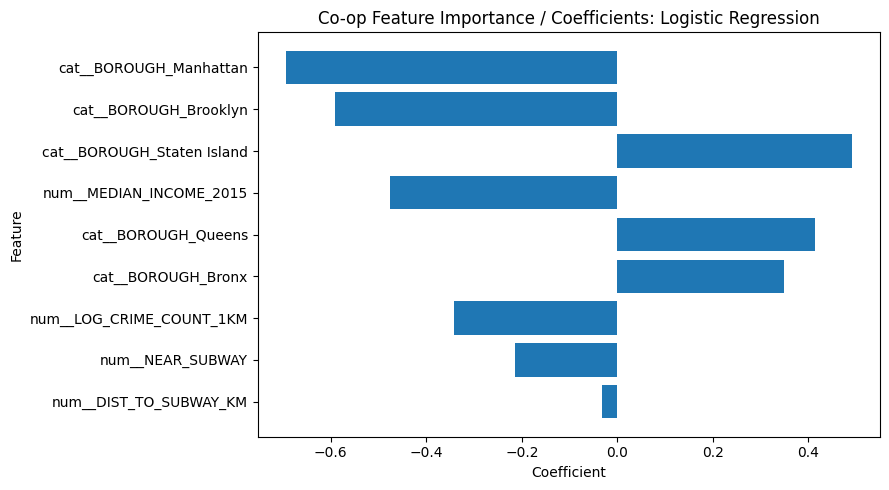

In [ ]:
# ============================================================
# 3. Co-op predictions, top neighborhoods, and feature explanation
# ============================================================

coop_model_ready["PRED_HIGH_RETURN_PROB"] = best_model_coop.predict_proba(X_coop)[:, 1]
coop_model_ready["PRED_HIGH_RETURN"] = (coop_model_ready["PRED_HIGH_RETURN_PROB"] >= 0.50).astype(int)

final_coop_results = (
    coop_model_ready[[
        "BOROUGH", "NEIGHBORHOOD", "HIGH_RETURN", "PRED_HIGH_RETURN",
        "PRED_HIGH_RETURN_PROB", "ANNUALIZED_RETURN", "EARLY_PRICE", "LATE_PRICE",
        "EARLY_SALES_COUNT", "LATE_SALES_COUNT", "CRIME_COUNT_1KM",
        "MEDIAN_INCOME_2015", "DIST_TO_SUBWAY_KM", "NEAR_SUBWAY"
    ]]
    .sort_values("PRED_HIGH_RETURN_PROB", ascending=False)
    .reset_index(drop=True)
)

final_coop_results["PRED_HIGH_RETURN_PROB"] = final_coop_results["PRED_HIGH_RETURN_PROB"].round(3)
final_coop_results["ANNUALIZED_RETURN"] = final_coop_results["ANNUALIZED_RETURN"].round(4)
final_coop_results["DIST_TO_SUBWAY_KM"] = final_coop_results["DIST_TO_SUBWAY_KM"].round(3)

print("Top predicted Co-op neighborhoods:")
display(final_coop_results.head(15))

# Visualization for the final report: top 10 predicted Co-op neighborhoods.
top10_coop = final_coop_results.head(10).copy()
top10_coop["LABEL"] = top10_coop["BOROUGH"] + " - " + top10_coop["NEIGHBORHOOD"]

plt.figure(figsize=(9, 5))
plt.barh(top10_coop["LABEL"], top10_coop["PRED_HIGH_RETURN_PROB"])
plt.xlabel("Predicted Probability of High Co-op Appreciation")
plt.ylabel("Neighborhood")
plt.title("Top 10 Predicted High-Appreciation Co-op Neighborhoods")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


print("Lowest predicted Co-op neighborhoods:")
display(final_coop_results.tail(15))

# Model explanation / feature importance.
feature_names = best_model_coop.named_steps["preprocess"].get_feature_names_out()
model_step = best_model_coop.named_steps["model"]

if hasattr(model_step, "feature_importances_"):
    importance_df = pd.DataFrame({"Feature": feature_names, "Importance": model_step.feature_importances_})
    value_col = "Importance"
elif hasattr(model_step, "coef_"):
    importance_df = pd.DataFrame({"Feature": feature_names, "Coefficient": model_step.coef_[0]})
    value_col = "Coefficient"
else:
    importance_df = pd.DataFrame()
    value_col = None

if not importance_df.empty:
    importance_df = importance_df.sort_values(value_col, key=lambda s: s.abs(), ascending=False)
    display(importance_df)

    plt.figure(figsize=(9, 5))
    plt.barh(importance_df["Feature"], importance_df[value_col])
    plt.xlabel(value_col)
    plt.ylabel("Feature")
    plt.title(f"Co-op Feature Importance / Coefficients: {best_model_name}")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

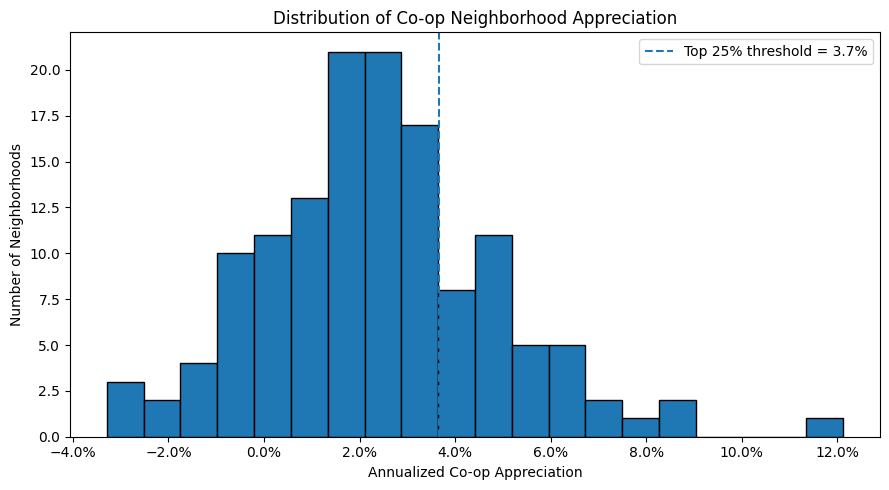

In [ ]:
import matplotlib.ticker as mtick

plt.figure(figsize=(9, 5))
plt.hist(coop_model["ANNUALIZED_RETURN"], bins=20, edgecolor="black")
plt.axvline(
    np.expm1(threshold_coop),
    linestyle="--",
    label=f"Top 25% threshold = {np.expm1(threshold_coop):.1%}"
)

plt.gca().xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
plt.xlabel("Annualized Co-op Appreciation")
plt.ylabel("Number of Neighborhoods")
plt.title("Distribution of Co-op Neighborhood Appreciation")
plt.legend()
plt.tight_layout()
plt.show()

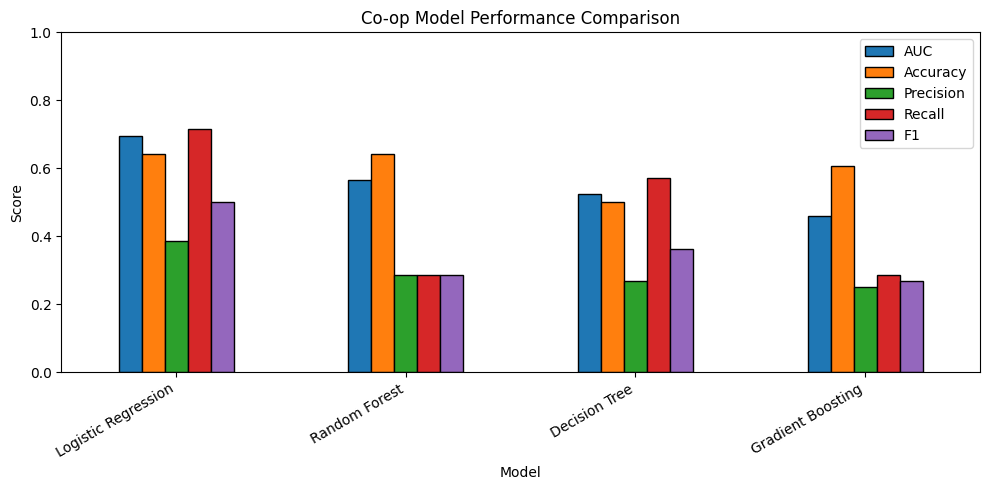

In [ ]:
performance_plot = results_coop_df.set_index("Model")[["AUC", "Accuracy", "Precision", "Recall", "F1"]]

performance_plot.plot(kind="bar", figsize=(10, 5), edgecolor="black")

plt.ylabel("Score")
plt.title("Co-op Model Performance Comparison")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

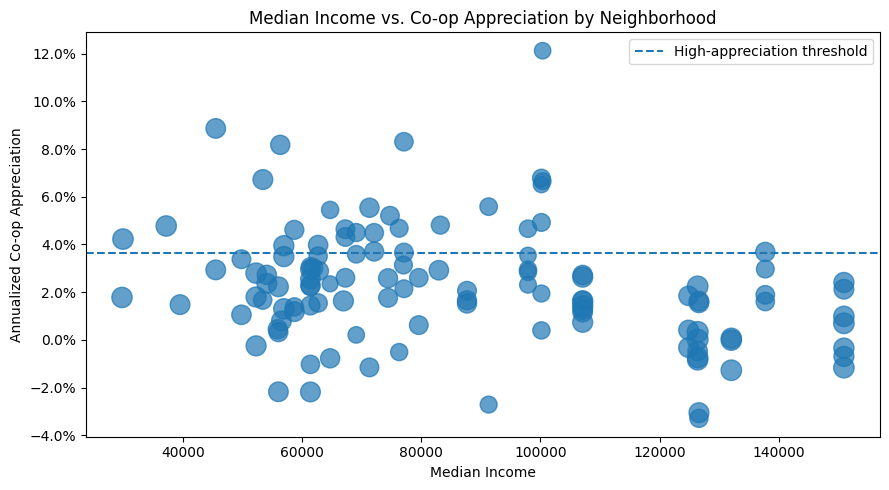

In [ ]:
scatter_df = coop_model.dropna(subset=["MEDIAN_INCOME_2015", "ANNUALIZED_RETURN"]).copy()

plt.figure(figsize=(9, 5))
plt.scatter(
    scatter_df["MEDIAN_INCOME_2015"],
    scatter_df["ANNUALIZED_RETURN"],
    s=30 + np.log1p(scatter_df["CRIME_COUNT_1KM"]) * 20,
    alpha=0.7
)

plt.axhline(np.expm1(threshold_coop), linestyle="--", label="High-appreciation threshold")

plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
plt.xlabel("Median Income")
plt.ylabel("Annualized Co-op Appreciation")
plt.title("Median Income vs. Co-op Appreciation by Neighborhood")
plt.legend()
plt.tight_layout()
plt.show()

Business Interpretation
The co-op model helps translate neighborhood conditions into a business question: which neighborhoods are more likely to experience above-average property appreciation? Instead of looking only at past sale prices, the model considers neighborhood-level factors such as income, subway access, and crime activity to estimate whether a co-op neighborhood is more likely to outperform the appreciation threshold.

In business terms, the results suggest that neighborhood quality and accessibility matter when predicting co-op appreciation. Co-ops in higher-income neighborhoods may have stronger appreciation potential because buyers are often willing to pay more in areas with stronger household purchasing power, better amenities, and more stable demand. Subway access can also improve appreciation potential because convenient transportation makes a neighborhood more attractive to buyers and commuters. On the other hand, higher crime activity may reduce appreciation potential because safety concerns can lower buyer demand or make a neighborhood feel riskier.

However, the model should not be interpreted as a perfect predictor. The results show that these neighborhood factors are useful, but they do not explain everything about co-op appreciation. Other factors, such as building condition, maintenance fees, interest rates, school quality, neighborhood development, and overall housing market trends, may also affect property values.

##Condos

In [ ]:
condo = prop[prop['SEGMENT'] == 'Condo'].copy()
print("Condo properties:", condo.shape[0])
print(condo['HIGH_RETURN'].value_counts())

Condo properties: 2899
HIGH_RETURN
0    2174
1     725
Name: count, dtype: int64


In [ ]:
print("Annualized Return Summary — Condo:")
print(condo['ANNUALIZED_RETURN'].describe().round(4))


Annualized Return Summary — Condo:
count    2899.0000
mean        0.0279
std         0.1317
min        -0.4966
25%        -0.0218
50%         0.0165
75%         0.0613
max         0.9777
Name: ANNUALIZED_RETURN, dtype: float64


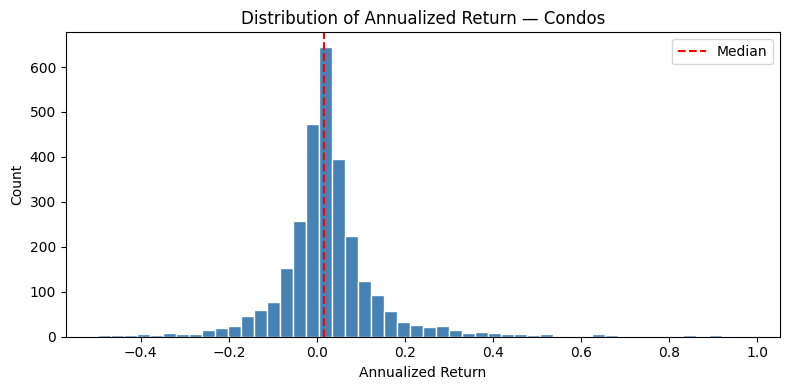

High Return Target Rate — Condo:
HIGH_RETURN
0    2174
1     725
Name: count, dtype: int64
HIGH_RETURN
0    0.75
1    0.25
Name: proportion, dtype: float64


In [ ]:
plt.figure(figsize=(8, 4))
plt.hist(condo['ANNUALIZED_RETURN'], bins=50, color='steelblue', edgecolor='white')
plt.axvline(condo['ANNUALIZED_RETURN'].median(), color='red', linestyle='--', label='Median')
plt.xlabel('Annualized Return')
plt.ylabel('Count')
plt.title('Distribution of Annualized Return — Condos')
plt.legend()
plt.tight_layout()
plt.show()

# Target rate
print("High Return Target Rate — Condo:")
print(condo['HIGH_RETURN'].value_counts())
print(condo['HIGH_RETURN'].value_counts(normalize=True).round(3))

# NOTE:
# We expect approximately 25% of properties to be labeled HIGH_RETURN = 1
# because the threshold is set at the 75th percentile within this segment.
# Any significant deviation may indicate ties at the threshold boundary.

Feature Averages by Borough — Condo:


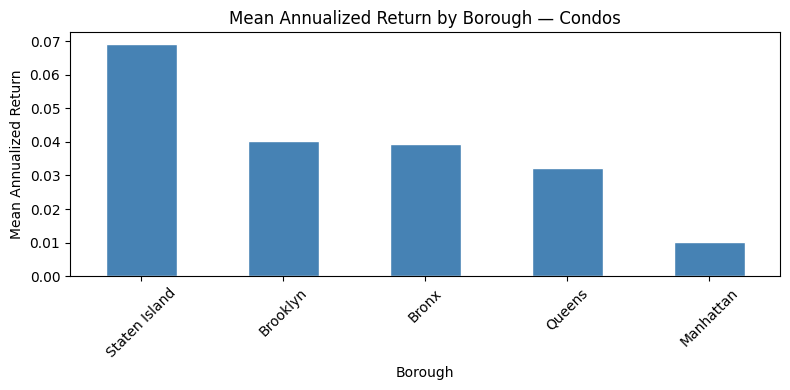

In [ ]:
print("Feature Averages by Borough — Condo:")
condo.groupby('BOROUGH')[['crime_count', 'DIST_TO_SUBWAY_KM', 'ANNUALIZED_RETURN']].mean().round(4)

# Return by borough (bar chart)
borough_summary_condo = condo.groupby('BOROUGH')['ANNUALIZED_RETURN'].mean().sort_values(ascending=False)

plt.figure(figsize=(8, 4))
borough_summary_condo.plot(kind='bar', color='steelblue', edgecolor='white')
plt.xlabel('Borough')
plt.ylabel('Mean Annualized Return')
plt.title('Mean Annualized Return by Borough — Condos')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



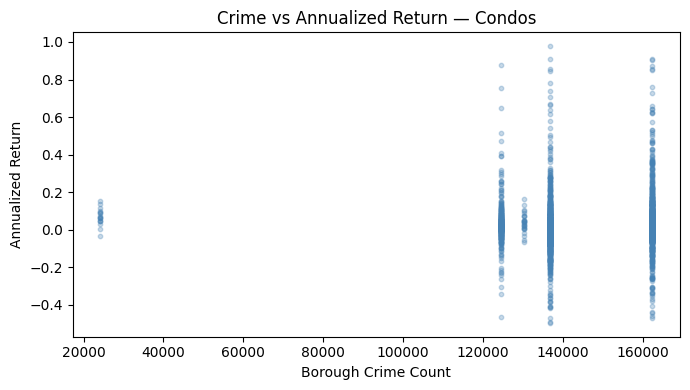

Correlation — Crime vs Return: 0.0476


In [ ]:
# Crime vs return scatter
plt.figure(figsize=(7, 4))
plt.scatter(condo['crime_count'], condo['ANNUALIZED_RETURN'], alpha=0.3, color='steelblue', s=10)
plt.xlabel('Borough Crime Count')
plt.ylabel('Annualized Return')
plt.title('Crime vs Annualized Return — Condos')
plt.tight_layout()
plt.show()

print("Correlation — Crime vs Return:",
      condo[['crime_count', 'ANNUALIZED_RETURN']].corr().iloc[0, 1].round(4))

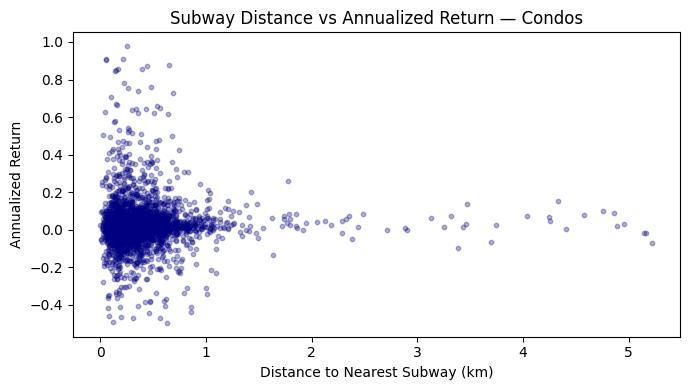

Correlation — Subway Distance vs Return: 0.0038


In [ ]:
plt.figure(figsize=(7, 4))
plt.scatter(condo['DIST_TO_SUBWAY_KM'], condo['ANNUALIZED_RETURN'], alpha=0.3, color='navy', s=10)
plt.xlabel('Distance to Nearest Subway (km)')
plt.ylabel('Annualized Return')
plt.title('Subway Distance vs Annualized Return — Condos')
plt.tight_layout()
plt.show()

print("Correlation — Subway Distance vs Return:",
      condo[['DIST_TO_SUBWAY_KM', 'ANNUALIZED_RETURN']].corr().iloc[0, 1].round(4))

In [ ]:
features_condo = ['crime_count', 'DIST_TO_SUBWAY_KM', 'NEAR_SUBWAY']
target_condo   = 'HIGH_RETURN'

# Check missingness
print(condo[features_condo + [target_condo]].isnull().sum())

# Drop any rows with missing values in these columns
condo = condo.dropna(subset=features_condo + [target_condo])
print("After dropping nulls:", condo.shape[0])

crime_count          0
DIST_TO_SUBWAY_KM    0
NEAR_SUBWAY          0
HIGH_RETURN          0
dtype: int64
After dropping nulls: 2899


In [ ]:
borough_dummies_condo = [c for c in condo.columns if c.startswith('BOROUGH_')]
features_condo = ['crime_count', 'DIST_TO_SUBWAY_KM', 'NEAR_SUBWAY'] + borough_dummies_condo

print("Borough dummies found:", borough_dummies_condo)
print("Features used:", features_condo)

Borough dummies found: []
Features used: ['crime_count', 'DIST_TO_SUBWAY_KM', 'NEAR_SUBWAY']


In [ ]:
from sklearn.model_selection import train_test_split

X_condo = condo[features_condo]
y_condo = condo[target_condo]

X_train_condo, X_test_condo, y_train_condo, y_test_condo = train_test_split(
    X_condo, y_condo, test_size=0.2, random_state=42, stratify=y_condo
)

print("Train size:", X_train_condo.shape[0])
print("Test size :", X_test_condo.shape[0])

Train size: 2319
Test size : 580


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler_condo = StandardScaler()
X_train_condo_scaled = scaler_condo.fit_transform(X_train_condo)
X_test_condo_scaled  = scaler_condo.transform(X_test_condo)

In [ ]:
from sklearn.linear_model  import LogisticRegression
from sklearn.tree          import DecisionTreeClassifier
from sklearn.ensemble      import RandomForestClassifier, GradientBoostingClassifier

models_condo = {
    'Logistic Regression' : LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    'Decision Tree'       : DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42),
    'Random Forest'       : RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42),
    'Gradient Boosting'   : GradientBoostingClassifier(n_estimators=100, random_state=42),
}

trained_condo = {}
for name, model in models_condo.items():
    if name == 'Logistic Regression':
        model.fit(X_train_condo_scaled, y_train_condo)
    else:
        model.fit(X_train_condo, y_train_condo)
    trained_condo[name] = model
    print(f"{name} trained.")


Logistic Regression trained.
Decision Tree trained.
Random Forest trained.
Gradient Boosting trained.


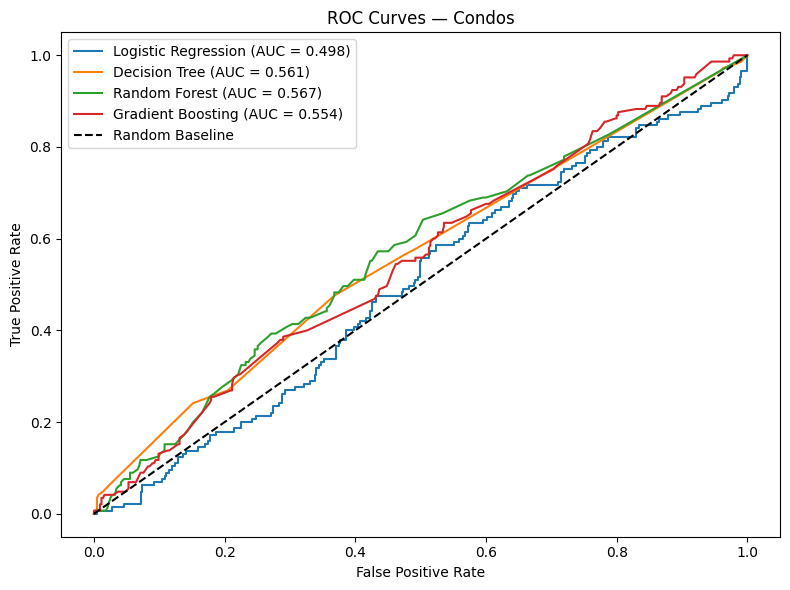


AUC Summary — Condos:
  Random Forest             AUC = 0.567
  Decision Tree             AUC = 0.561
  Gradient Boosting         AUC = 0.554
  Logistic Regression       AUC = 0.498


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(8, 6))

auc_results_condo = {}

for name, model in trained_condo.items():
    if name == 'Logistic Regression':
        probs = model.predict_proba(X_test_condo_scaled)[:, 1]
    else:
        probs = model.predict_proba(X_test_condo)[:, 1]

    fpr, tpr, _ = roc_curve(y_test_condo, probs)
    auc = roc_auc_score(y_test_condo, probs)
    auc_results_condo[name] = auc
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], 'k--', label='Random Baseline')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves — Condos')
plt.legend()
plt.tight_layout()
plt.show()

# AUC summary table
print("\nAUC Summary — Condos:")
for name, auc in sorted(auc_results_condo.items(), key=lambda x: -x[1]):
    print(f"  {name:<25} AUC = {auc:.3f}")


In [ ]:
from sklearn.metrics import classification_report

for name, model in trained_condo.items():
    if name == 'Logistic Regression':
        preds = model.predict(X_test_condo_scaled)
    else:
        preds = model.predict(X_test_condo)

    print(f"\n{'='*40}")
    print(f"  {name}")
    print(f"{'='*40}")
    print(classification_report(y_test_condo, preds, target_names=['Low Return', 'High Return']))


  Logistic Regression
              precision    recall  f1-score   support

  Low Return       0.77      0.50      0.61       435
 High Return       0.27      0.55      0.36       145

    accuracy                           0.51       580
   macro avg       0.52      0.53      0.48       580
weighted avg       0.64      0.51      0.54       580


  Decision Tree
              precision    recall  f1-score   support

  Low Return       0.78      0.63      0.70       435
 High Return       0.30      0.48      0.37       145

    accuracy                           0.59       580
   macro avg       0.54      0.55      0.53       580
weighted avg       0.66      0.59      0.62       580


  Random Forest
              precision    recall  f1-score   support

  Low Return       0.77      0.77      0.77       435
 High Return       0.32      0.32      0.32       145

    accuracy                           0.66       580
   macro avg       0.55      0.55      0.55       580
weighted avg     

Best model for Condo: Random Forest (AUC = 0.567)
 Decile  High_Return_Rate     Lift
      1          0.310345 1.241379
      2          0.344828 1.379310
      3          0.327586 1.310345
      4          0.224138 0.896552
      5          0.275862 1.103448
      6          0.206897 0.827586
      7          0.172414 0.689655
      8          0.206897 0.827586
      9          0.206897 0.827586
     10          0.224138 0.896552


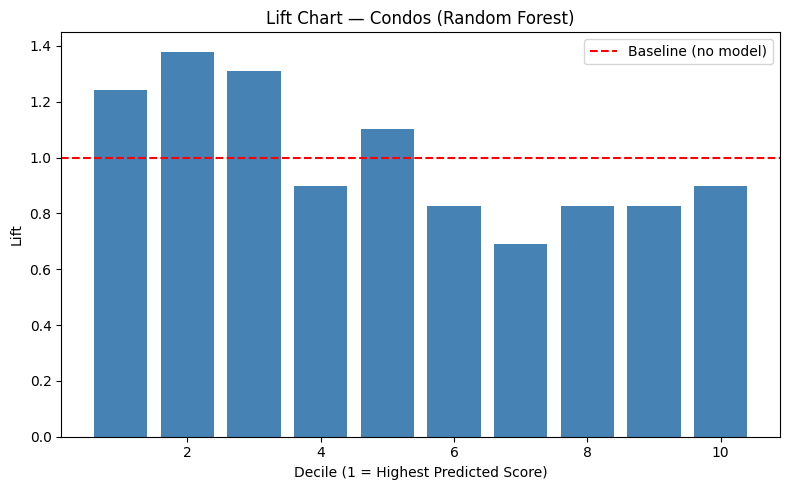

In [ ]:
import numpy as np

best_name_condo  = max(auc_results_condo, key=auc_results_condo.get)
best_model_condo = trained_condo[best_name_condo]
print(f"Best model for Condo: {best_name_condo} (AUC = {auc_results_condo[best_name_condo]:.3f})")

if best_name_condo == 'Logistic Regression':
    probs_condo = best_model_condo.predict_proba(X_test_condo_scaled)[:, 1]
else:
    probs_condo = best_model_condo.predict_proba(X_test_condo)[:, 1]

lift_df_condo = pd.DataFrame({'prob': probs_condo, 'actual': y_test_condo.values})
lift_df_condo = lift_df_condo.sort_values('prob', ascending=False).reset_index(drop=True)
lift_df_condo['decile'] = pd.qcut(lift_df_condo.index, 10, labels=False) + 1

lift_summary_condo = lift_df_condo.groupby('decile')['actual'].mean().reset_index()
lift_summary_condo.columns = ['Decile', 'High_Return_Rate']
lift_summary_condo['Lift'] = lift_summary_condo['High_Return_Rate'] / lift_df_condo['actual'].mean()

print(lift_summary_condo.to_string(index=False))

plt.figure(figsize=(8, 5))
plt.bar(lift_summary_condo['Decile'], lift_summary_condo['Lift'], color='steelblue')
plt.axhline(1, color='red', linestyle='--', label='Baseline (no model)')
plt.xlabel('Decile (1 = Highest Predicted Score)')
plt.ylabel('Lift')
plt.title(f'Lift Chart — Condos ({best_name_condo})')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
print("Model Comparison — Condos:")
print(f"{'Model':<25} {'AUC':>6}")
print("-" * 33)
for name, auc in sorted(auc_results_condo.items(), key=lambda x: -x[1]):
    marker = " ← SELECTED" if name == best_name_condo else ""
    print(f"{name:<25} {auc:>6.3f}{marker}")

Model Comparison — Condos:
Model                        AUC
---------------------------------
Random Forest              0.567 ← SELECTED
Decision Tree              0.561
Gradient Boosting          0.554
Logistic Regression        0.498


Feature Importance — Condos (Random Forest):
          Feature  Importance
DIST_TO_SUBWAY_KM    0.975949
      crime_count    0.022756
      NEAR_SUBWAY    0.001295


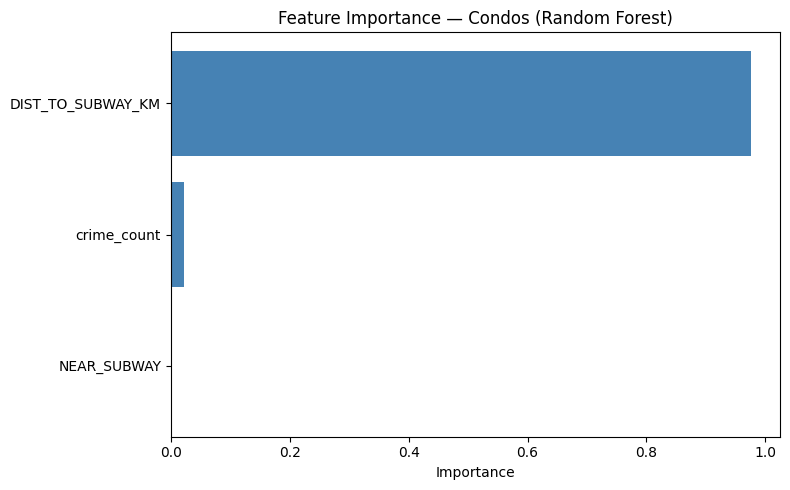

In [ ]:
if best_name_condo == 'Logistic Regression':
    importance_vals_condo  = np.abs(best_model_condo.coef_[0])
    importance_label_condo = 'Absolute Coefficient'
else:
    importance_vals_condo  = best_model_condo.feature_importances_
    importance_label_condo = 'Importance'

importance_df_condo = pd.DataFrame({
    'Feature'   : features_condo,
    'Importance': importance_vals_condo
}).sort_values('Importance', ascending=False)

print(f"Feature Importance — Condos ({best_name_condo}):")
print(importance_df_condo.to_string(index=False))

plt.figure(figsize=(8, 5))
plt.barh(importance_df_condo['Feature'], importance_df_condo['Importance'], color='steelblue')
plt.xlabel(importance_label_condo)
plt.title(f'Feature Importance — Condos ({best_name_condo})')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()